Fase 1 (Comprensión del negocio)

Proyecto final – Caso B: Distribuidora TransAndes

Problema de la empresa

TransAndes tiene problemas con las entregas tardías: en 2025, cerca de 3 de cada 10 pedidos llegaron después de lo prometido. Esto genera quejas, penalidades y pérdida de clientes. La empresa quiere usar la información disponible al despachar, como la distancia, el clima y el vehículo, para predecir qué pedidos podrían llegar tarde y tomar medidas a tiempo.

¿Qué es un acierto y qué es un error?

Un acierto es cuando el modelo predice correctamente si un pedido llegará tarde o a tiempo. Un error es cuando la predicción no coincide con lo que ocurre.

Falso negativo: el modelo dice que un pedido llegará a tiempo pero llega tarde.

Falso positivo: el modelo dice que un pedido llegará tarde pero realmente llega a tiempo.

¿Qué error es más costoso?

Para TransAndes, el falso negativo es más costoso porque la empresa no toma medidas para evitar un retraso real. Esto puede causar quejas, penalidades y pérdida de clientes. En cambio, un falso positivo puede generar gastos extra innecesarios, pero permite prevenir posibles problemas.

Por eso, conviene priorizar el recall de la clase Sí (entrega tardía) así el modelo busca detectar la mayor cantidad posible de pedidos que realmente llegarán tarde.

Fase 2 (Comprensión de los datos)

1. Importar librerias y cargar datos

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

df = pd.read_csv("logistica_entregas.csv")

df["fecha_despacho"] = pd.to_datetime(df["fecha_despacho"])

print("Base de datos cargada correctamente")
df.head()


Base de datos cargada correctamente


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.9,115.5,10.0,19.0,Lluvia,5.7,9.0,Empresa,Normal,193700.0,Sí
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.7,264.3,NaN,17.0,Lluvia,3.2,4.0,NaN,Normal,361300.0,Sí
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.6,NaN,7.0,20.0,Soleado,NaN,5.0,Hogar,Express,170600.0,No
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.1,9.2,1.0,6.0,Soleado,10.2,5.0,Empresa,Normal,622400.0,No
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.2,260.5,1.0,5.0,Lluvia,6.5,15.0,Hogar,Normal,406500.0,No


2. Punto 1 (Dimensiones, tipos de datos e información general)

In [ ]:

print("Dimensiones:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

print("\nInformación del DataFrame:")
df.info()

print("\nEstadísticas descriptivas:")
display(df.describe())

display(df.describe(include="object"))

print("Duplicados exactos:", df.duplicated().sum())


Dimensiones: (8035, 17)

Columnas:
['id_pedido', 'fecha_despacho', 'dia_semana', 'centro_distribucion', 'zona_destino', 'tipo_vehiculo', 'distancia_km', 'peso_kg', 'num_paradas', 'hora_salida', 'clima', 'experiencia_conductor_anios', 'edad_vehiculo_anios', 'tipo_cliente', 'prioridad', 'valor_pedido_COP', 'entrega_tardia']

Tipos de datos:
id_pedido                                 str
fecha_despacho                 datetime64[us]
dia_semana                                str
centro_distribucion                       str
zona_destino                              str
tipo_vehiculo                             str
distancia_km                          float64
peso_kg                               float64
num_paradas                           float64
hora_salida                           float64
clima                                     str
experiencia_conductor_anios           float64
edad_vehiculo_anios                   float64
tipo_cliente                              str
prioridad      

,fecha_despacho,distancia_km,peso_kg,num_paradas,hora_salida,experiencia_conductor_anios,edad_vehiculo_anios,valor_pedido_COP
count,8035,7633.000000,7391.000000,7550.000000,7713.000000,7149.000000,7475.000000,7.634000e+03
mean,2025-07-01 06:14:44.430616,34.213939,370.062793,6.557616,12.529366,4.979857,7.351171,3.014746e+05
min,2025-01-01 00:00:00,-144.100000,0.000000,0.000000,5.000000,0.100000,0.000000,1.130000e+04
25%,2025-03-31 00:00:00,11.300000,10.450000,4.000000,9.000000,2.400000,3.000000,1.258000e+05
50%,2025-06-30 00:00:00,19.400000,143.300000,6.000000,12.000000,4.200000,7.000000,2.160000e+05
75%,2025-09-29 00:00:00,43.500000,328.050000,9.000000,16.000000,6.600000,11.000000,3.748750e+05
max,2025-12-31 00:00:00,299.000000,6341.200000,23.000000,30.000000,30.000000,15.000000,5.752400e+06
std,NaN,36.319649,616.095060,3.439742,4.594636,3.485612,4.584695,2.963054e+05


/var/folders/fj/vv_8ch1n5clgvfc2wcqc2qvc0000gn/T/ipykernel_5401/1643715749.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,id_pedido,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,clima,tipo_cliente,prioridad,entrega_tardia
count,8035,8035,8035,8035,8035,7311,7792,8035,8035
unique,8000,7,10,3,7,4,3,2,2
top,P-06259,Lunes,Cali,Urbana,Furgón,Soleado,Hogar,Normal,No
freq,2,1206,2688,4379,3487,2891,3541,6056,5513


Duplicados exactos: 35


Interpretación del punto 1

La base de datos de TransAndes contiene 8.035 registros y 17 columnas. Incluye información de los pedidos, como distancia, peso, clima, vehículo y experiencia del conductor. Encontramos variables numéricas y categóricas, además de la fecha de despacho. También identificamos 35 registros duplicados y algunos valores sospechosos, como distancias negativas y horas de salida superiores a 23. Estos problemas deberán tratarse en la fase 3 antes de entrenar los modelos.

3. Punto 2 (Valores nulos por columna)

In [ ]:

nulos = df.isna().sum()

porcentaje_nulos = df.isna().mean() * 100

tabla_nulos = pd.DataFrame({
    "Cantidad de nulos": nulos,
    "Porcentaje (%)": porcentaje_nulos.round(2)
})

tabla_nulos = tabla_nulos.sort_values(
    "Porcentaje (%)",
    ascending=False
)

display(tabla_nulos)


,Cantidad de nulos,Porcentaje (%)
experiencia_conductor_anios,886,11.03
clima,724,9.01
peso_kg,644,8.01
edad_vehiculo_anios,560,6.97
num_paradas,485,6.04
distancia_km,402,5.00
valor_pedido_COP,401,4.99
hora_salida,322,4.01
tipo_cliente,243,3.02
prioridad,0,0.00


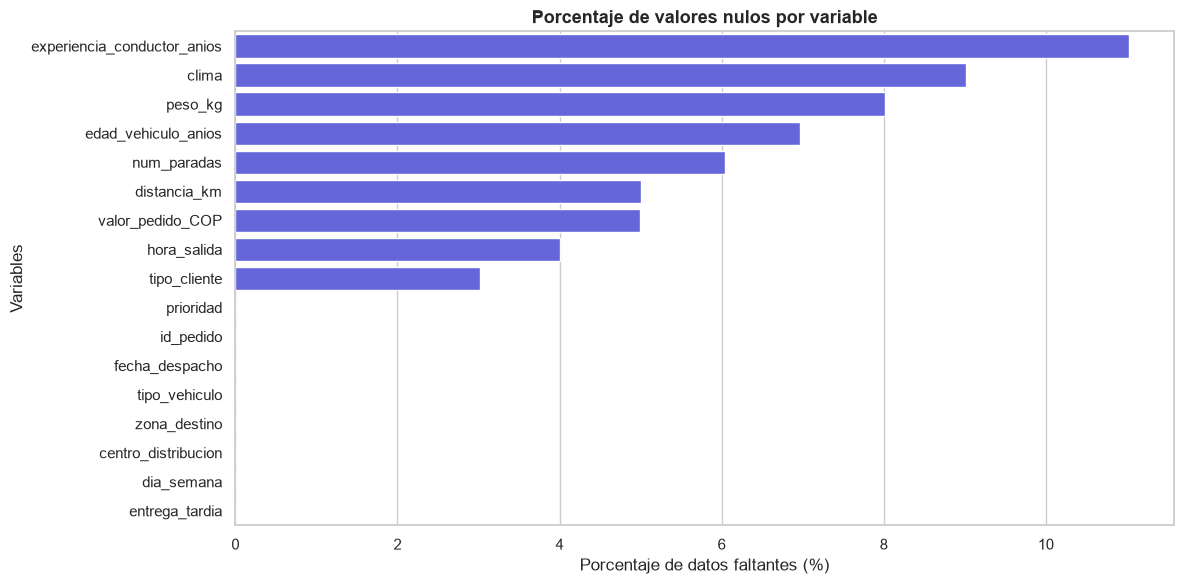

In [4]:

plt.figure(figsize=(12, 6))

sns.barplot(
    data=tabla_nulos.reset_index(),
    x="Porcentaje (%)",
    y="index",
    color="#5353EE"
)

plt.title("Porcentaje de valores nulos por variable")
plt.xlabel("Porcentaje de datos faltantes (%)")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()


Interpretación del punto 2

Se encontraron valores faltantes en nueve variables. La variable con mayor cantidad de nulos es la experiencia del conductor, con aproximadamente el 11 %, seguida del clima, con el 9 %, y el peso del pedido, con el 8 %. Estos datos faltantes pueden afectar la calidad de los análisis y de las futuras predicciones. Por eso será necesario definir estrategias para tratarlos durante la preparación de los datos.

4. Punto 3 (analisis univariado)

Distribución de las variables numéricas 

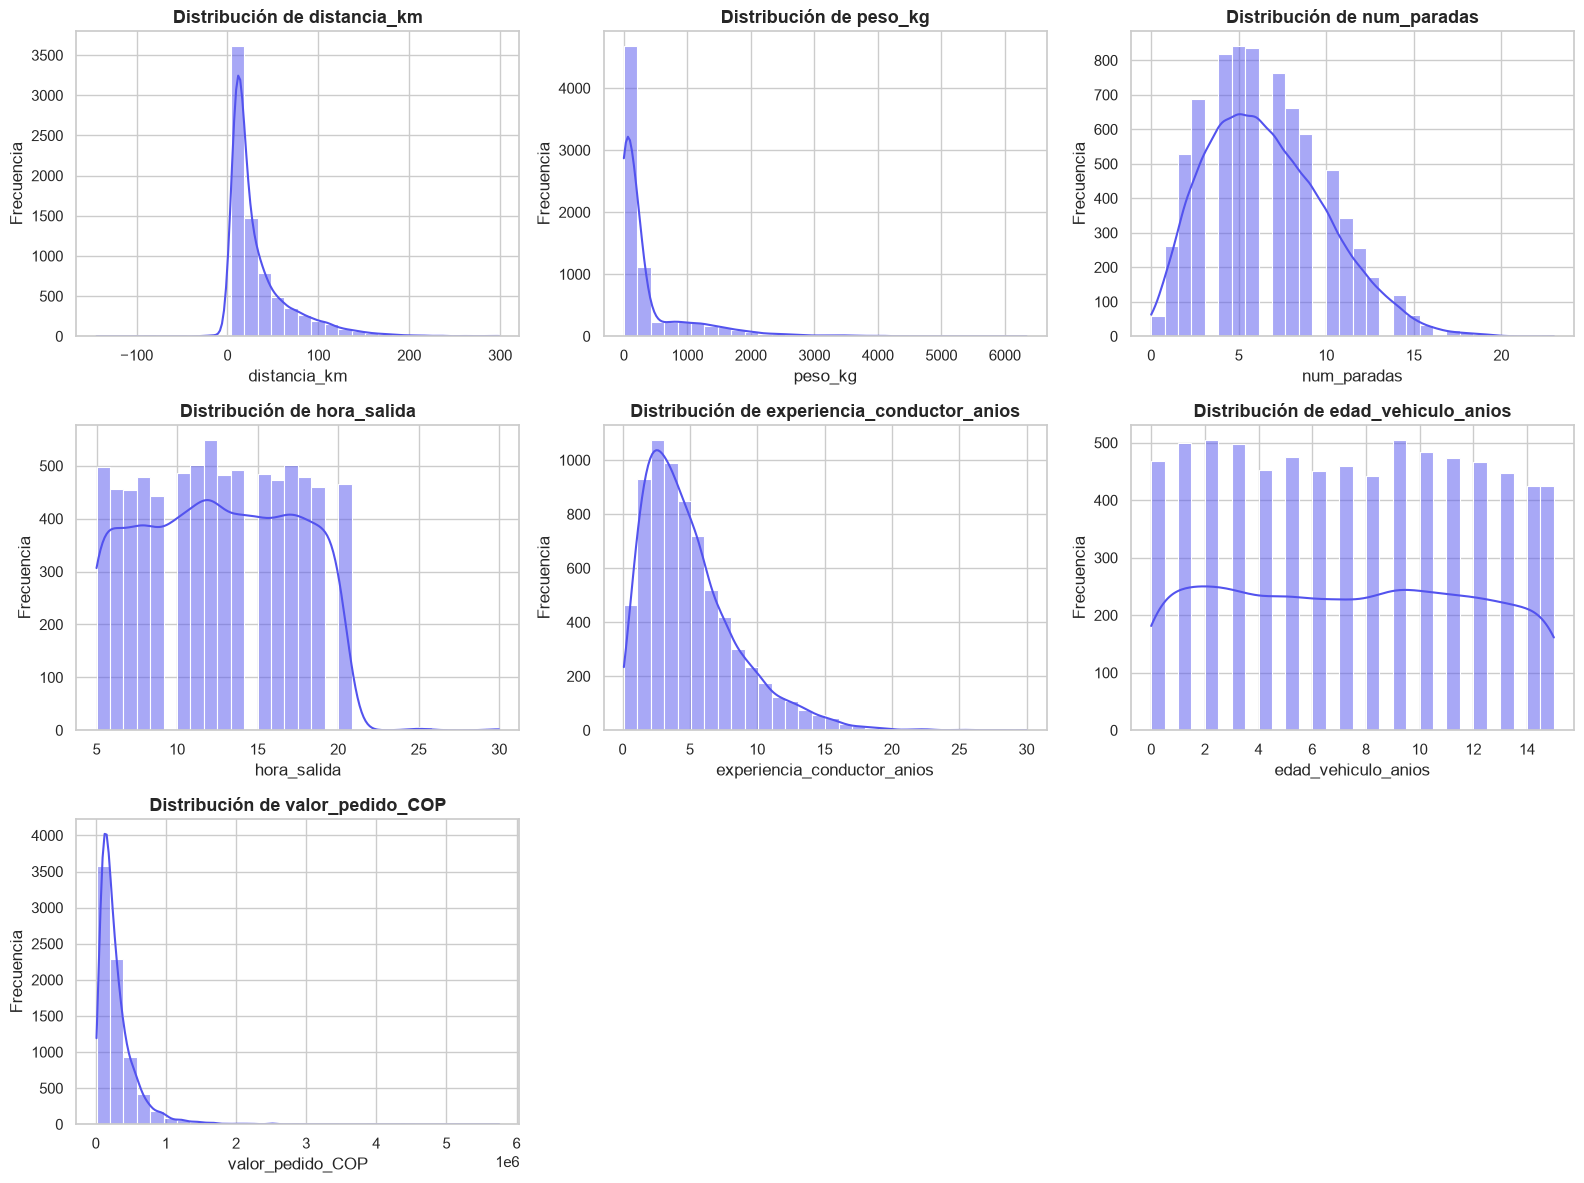

In [5]:

variables_num = [
    "distancia_km",
    "peso_kg",
    "num_paradas",
    "hora_salida",
    "experiencia_conductor_anios",
    "edad_vehiculo_anios",
    "valor_pedido_COP"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, var in enumerate(variables_num):
    sns.histplot(
        data=df,
        x=var,
        bins=30,
        kde=True,
        color="#5353EE",
        ax=axes[i]
    )

    axes[i].set_title(f"Distribución de {var}")
    axes[i].set_xlabel(var)
    axes[i].set_ylabel("Frecuencia")

for j in range(len(variables_num), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


 Interpretación  análisis univariado de variables numéricas

Al analizar las distribuciones de las variables numéricas de TransAndes, encontramos lo siguiente:

1. **Distancia (km):** La mayoría de los pedidos recorren distancias cortas, principalmente entre 0 y 50 km. Sin embargo, existen rutas mucho más largas y algunos valores negativos que pueden ser errores en los datos.

2. **Peso (kg):** La mayoría de los pedidos tienen pesos bajos, mientras que unos pocos presentan pesos muy elevados. Esto genera una distribución sesgada hacia la derecha.

3. **Número de paradas:** La mayor parte de las rutas tiene entre 3 y 10 paradas, siendo aproximadamente 5 o 6 las más frecuentes.

4. **Hora de salida:** Los despachos se concentran entre las 5:00 y las 21:00, con frecuencias relativamente similares. También aparecen algunos valores superiores a 23, que deben revisarse.

5. **Experiencia del conductor:** La mayoría de los conductores tiene entre 1 y 7 años de experiencia. A medida que aumentan los años, disminuye la cantidad de conductores.

6. **Edad del vehículo:** Los vehículos tienen edades distribuidas entre 0 y 15 años, sin que exista una concentración muy marcada en alguna edad específica.

7. **Valor del pedido (COP):** La mayoría de los pedidos tiene valores relativamente bajos, mientras que unos pocos alcanzan valores de varios millones de pesos. La distribución presenta un sesgo hacia la derecha.

Conclusión general

Las gráficas muestran que varias variables presentan distribuciones asimétricas y valores extremos, especialmente la distancia, el peso y el valor del pedido. También identificamos datos sospechosos, como distancias negativas y horas de salida fuera del rango esperado. Por lo tanto, será importante revisar y tratar estos valores en la fase 3 para mejorar la calidad de la información antes de construir los modelos predictivos.

Detectar valores extremos con boxplots

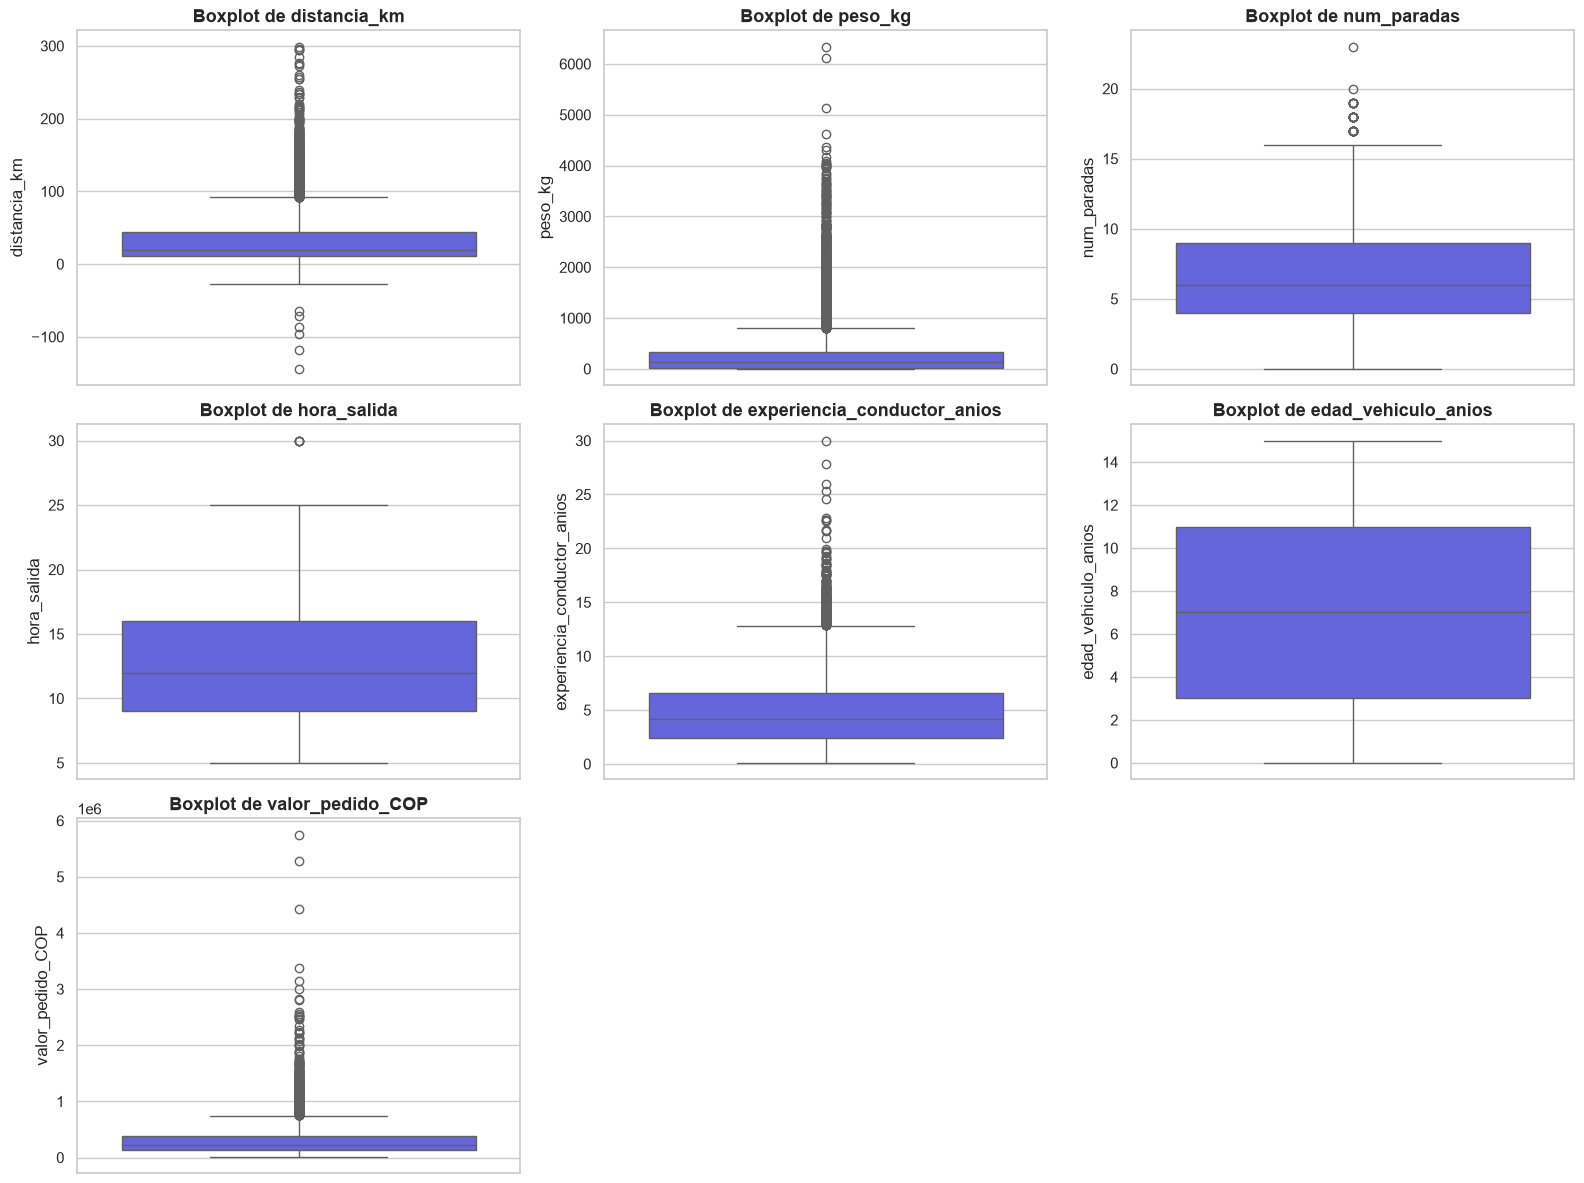

In [6]:

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, var in enumerate(variables_num):
    sns.boxplot(
        data=df,
        y=var,
        ax=axes[i],
        color="#5353EE"
    )

    axes[i].set_title(f"Boxplot de {var}")
    axes[i].set_ylabel(var)

for j in range(len(variables_num), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


Interpretación

Los histogramas muestran que las variables numéricas tienen distribuciones diferentes. Por ejemplo, la distancia promedio de los pedidos es de aproximadamente 34,21 km, mientras que la mediana es de 19,4 km, lo que indica que existen rutas considerablemente más largas que otras. También encontramos valores extremos y registros sospechosos, como distancias negativas, cero paradas y horas de salida superiores a 23. Estos resultados muestran que la base necesita una revisión de calidad antes del modelado.

Analisis de las variables categorícas 

In [ ]:

df_eda = df.copy()

df_eda["centro_distribucion"] = (
    df_eda["centro_distribucion"]
    .str.strip()
    .str.lower()
    .replace({
        "bogota": "bogotá",
        "medellin": "medellín"
    })
    .str.title()
)

df_eda["tipo_vehiculo"] = (
    df_eda["tipo_vehiculo"]
    .str.strip()
    .str.lower()
    .replace({
        "furgon": "furgón",
        "camion": "camión"
    })
    .str.title()
)

print(df_eda["centro_distribucion"].value_counts())
print(df_eda["tipo_vehiculo"].value_counts())


centro_distribucion
Cali            2769
Bogotá          2487
Medellín        1526
Barranquilla    1253
Name: count, dtype: int64
tipo_vehiculo
Furgón    3566
Moto      2852
Camión    1617
Name: count, dtype: int64


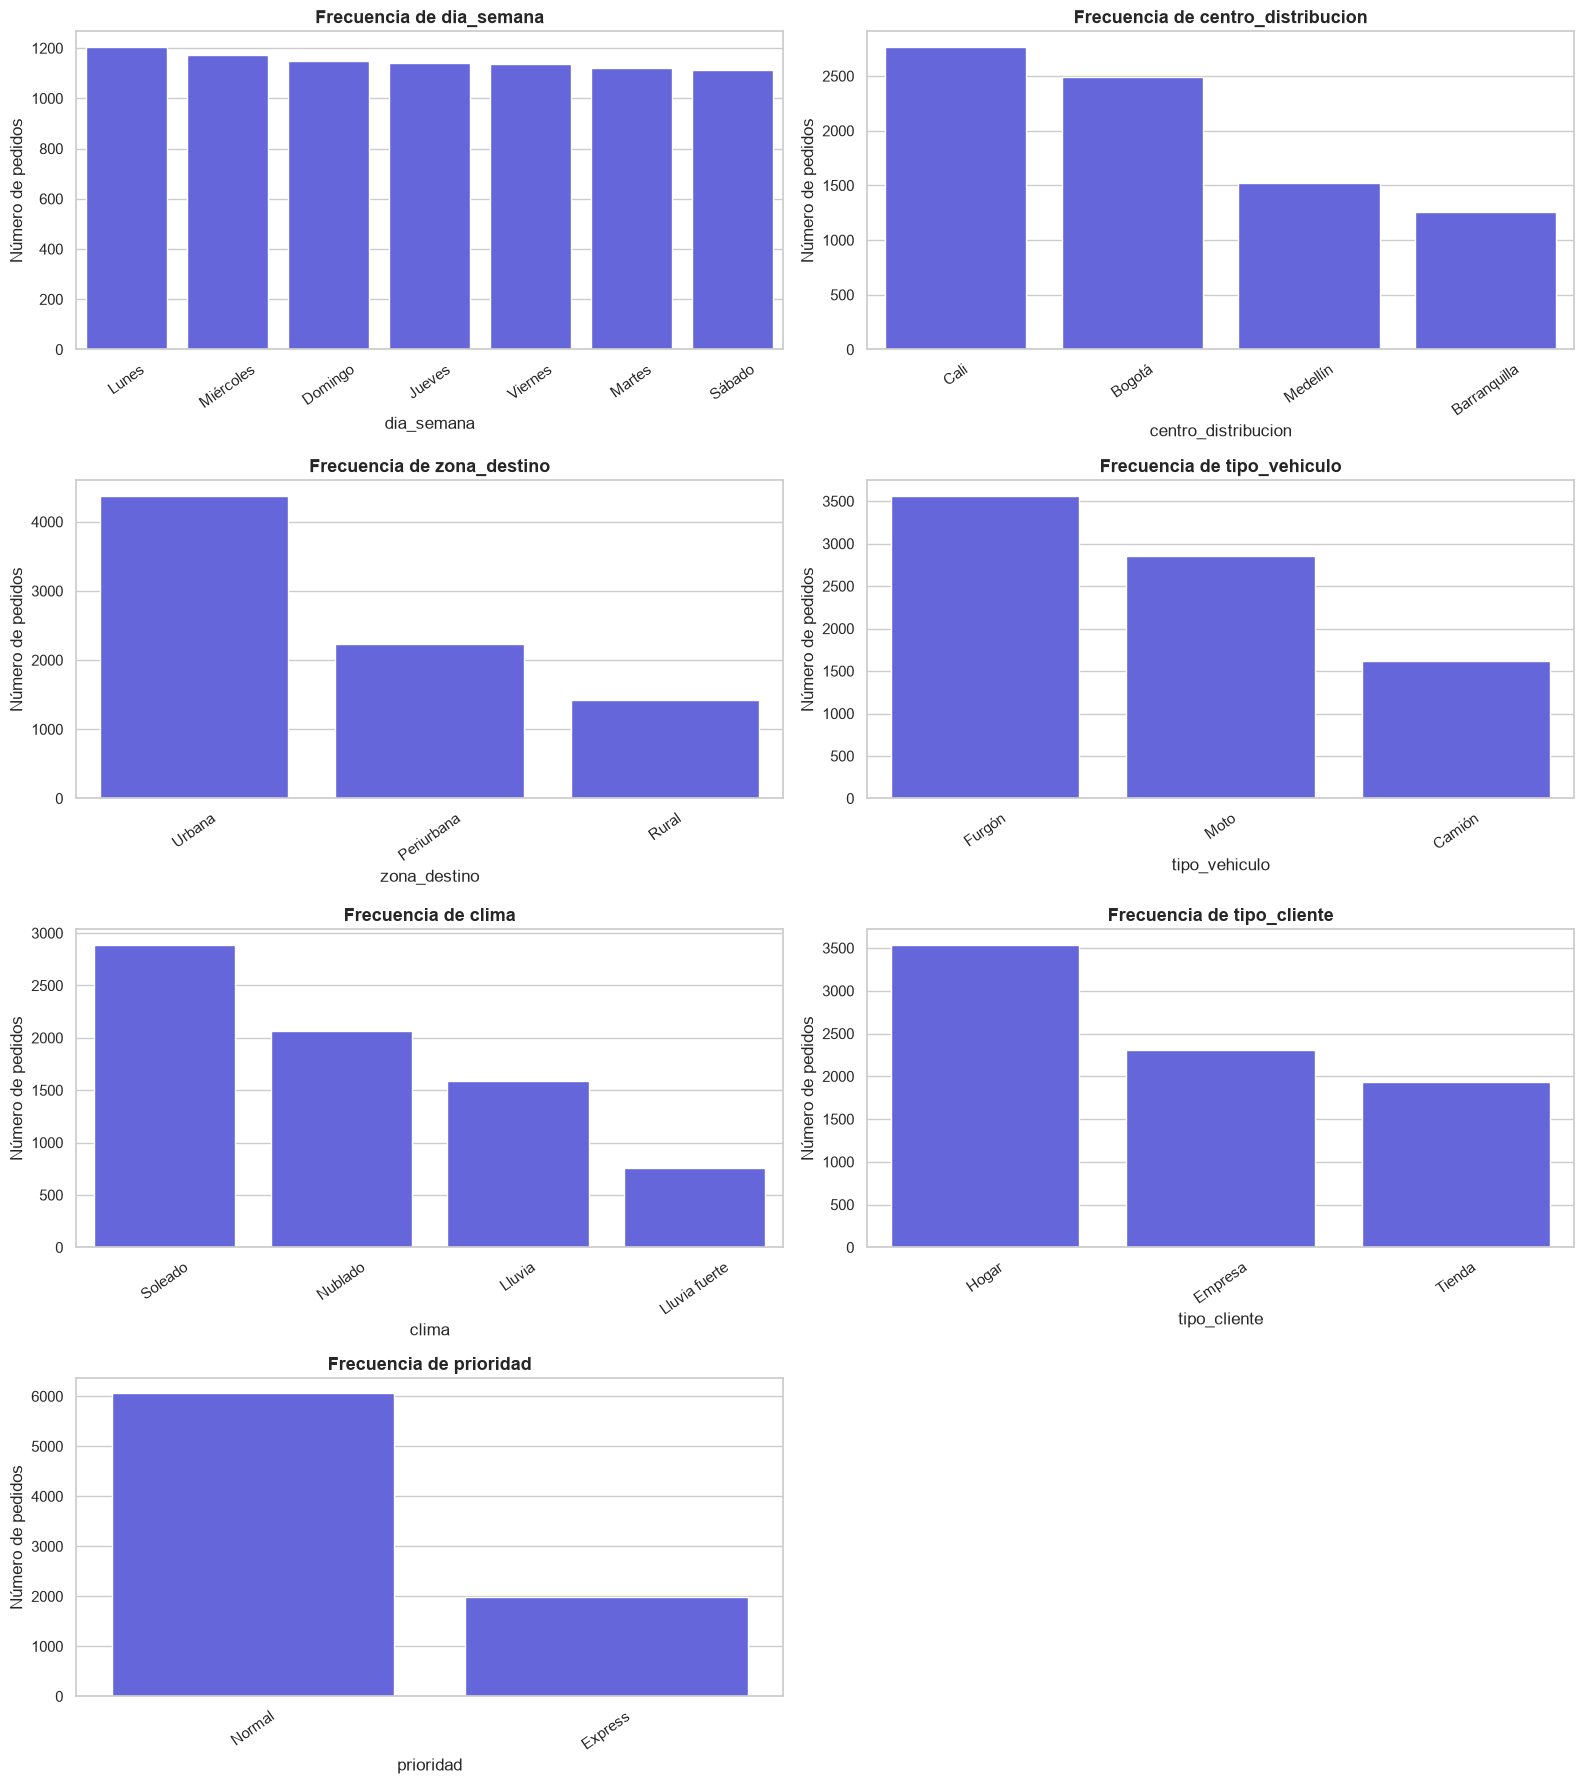

In [8]:

variables_cat = [
    "dia_semana",
    "centro_distribucion",
    "zona_destino",
    "tipo_vehiculo",
    "clima",
    "tipo_cliente",
    "prioridad"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, var in enumerate(variables_cat):

    orden = df_eda[var].value_counts().index

    sns.countplot(
        data=df_eda,
        x=var,
        order=orden,
        color="#5353EE",
        ax=axes[i]
    )

    axes[i].set_title(f"Frecuencia de {var}")
    axes[i].set_xlabel(var)
    axes[i].set_ylabel("Número de pedidos")
    axes[i].tick_params(axis="x", rotation=35)

for j in range(len(variables_cat), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


Interpretación del análisis univariado categórico

En la base de datos encontramos que Cali es el centro de distribución con mayor cantidad de pedidos, seguido de Bogotá. La mayoría de las entregas se realizan en zonas urbanas y el vehículo más utilizado es el furgón. También se observa que predominan los pedidos con prioridad normal y los clientes de tipo hogar. Estas frecuencias permiten comprender cómo está distribuida la operación logística de TransAndes.

5. Punto 4 (Análisis bivarriado)

Preparar la variable objetivo 

In [ ]:

df_eda["tarde_num"] = df_eda["entrega_tardia"].map({
    "Sí": 1,
    "No": 0
})

print(df_eda[["entrega_tardia", "tarde_num"]].head())

print(
    "Porcentaje general de entregas tardías:",
    round(df_eda["tarde_num"].mean() * 100, 2),
    "%"
)


  entrega_tardia  tarde_num
0             Sí          1
1             Sí          1
2             No          0
3             No          0
4             No          0
Porcentaje general de entregas tardías: 31.39 %


Grafica 1 (Entregas tardías de aceurdo a la zona de destino)

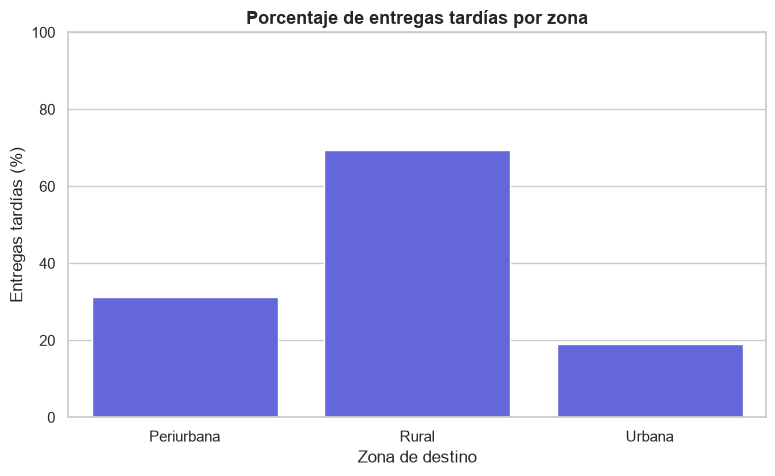

,zona_destino,tarde_num
0,Periurbana,31.151950
1,Rural,69.473684
2,Urbana,19.113953


In [10]:

# Porcentaje de retrasos por zona
tabla_zona = (
    df_eda.groupby("zona_destino")["tarde_num"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tabla_zona,
    x="zona_destino",
    y="tarde_num",
    color="#5353EE"
)

plt.title("Porcentaje de entregas tardías por zona")
plt.xlabel("Zona de destino")
plt.ylabel("Entregas tardías (%)")
plt.ylim(0, 100)
plt.show()

display(tabla_zona)


 Interpretación 

La gráfica muestra que las zonas rurales tienen el mayor porcentaje de entregas tardías, con aproximadamente un 69 % seguidas de las zonas periurbanas con un 31 % y las urbanas con un 19 %.

Esto indica que los pedidos destinados a zonas rurales presentan un riesgo mucho mayor de retrasarse, posiblemente debido a las distancias más largas y las dificultades de acceso.

**En conclusión**, la zona de destino es una variable importante para predecir las entregas tardías. Por eso, TransAndes debería prestar mayor atención a la planificación de las rutas rurales.

Grafica 2 (Entregas tardías segun clima)

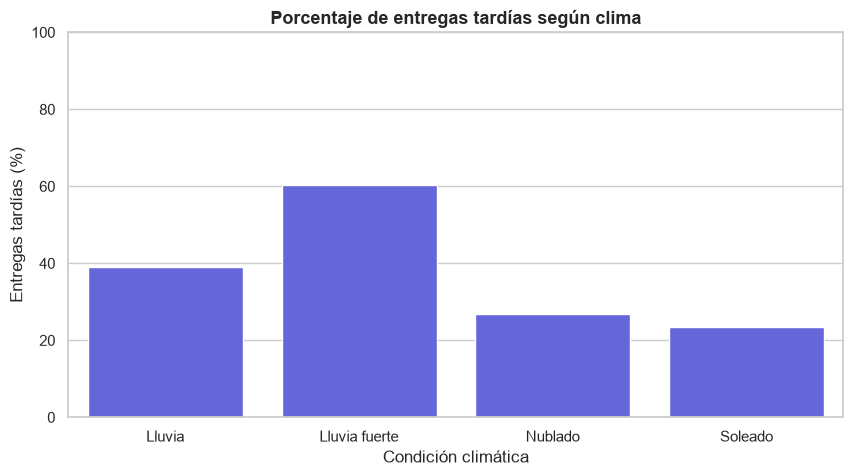

,clima,tarde_num
0,Lluvia,38.944724
1,Lluvia fuerte,60.263158
2,Nublado,26.789168
3,Soleado,23.348322


In [11]:

tabla_clima = (
    df_eda.groupby("clima")["tarde_num"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_clima,
    x="clima",
    y="tarde_num",
    color="#5353EE"
)

plt.title("Porcentaje de entregas tardías según clima")
plt.xlabel("Condición climática")
plt.ylabel("Entregas tardías (%)")
plt.ylim(0, 100)
plt.show()

display(tabla_clima)


Interpretación de la gráfica 2

El clima parece estar relacionado con los retrasos. Durante condiciones de lluvia fuerte, aproximadamente el 60 % de los pedidos llegan tarde, mientras que en días soleados el porcentaje es cercano al 23 %. Esto sugiere que las condiciones climáticas adversas aumentan el riesgo de incumplir los tiempos de entrega.

Grafica 3 (Entregas tardías segun el tipo de vehiculo)

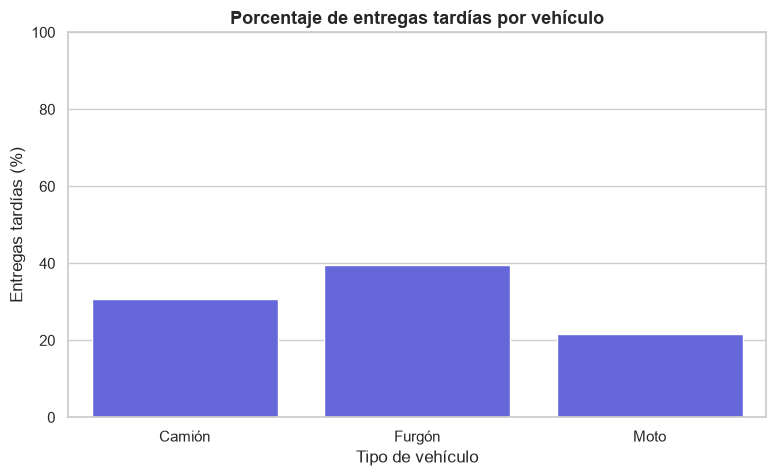

,tipo_vehiculo,tarde_num
0,Camión,30.797774
1,Furgón,39.540101
2,Moto,21.528752


In [12]:

tabla_vehiculo = (
    df_eda.groupby("tipo_vehiculo")["tarde_num"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tabla_vehiculo,
    x="tipo_vehiculo",
    y="tarde_num",
    color="#5353EE"
)

plt.title("Porcentaje de entregas tardías por vehículo")
plt.xlabel("Tipo de vehículo")
plt.ylabel("Entregas tardías (%)")
plt.ylim(0, 100)
plt.show()

display(tabla_vehiculo)


Interpretación de la gráfica 3

Los furgones presentan el mayor porcentaje de entregas tardías, cercano al 39 %, mientras que las motos tienen aproximadamente un 21 %. Esto indica que existe una diferencia en el desempeño observado según el vehículo utilizado. Sin embargo, también es necesario considerar que cada vehículo puede recorrer distancias y zonas diferentes.

Grafica 4 (Entregas tardías segun el centro de distribución)

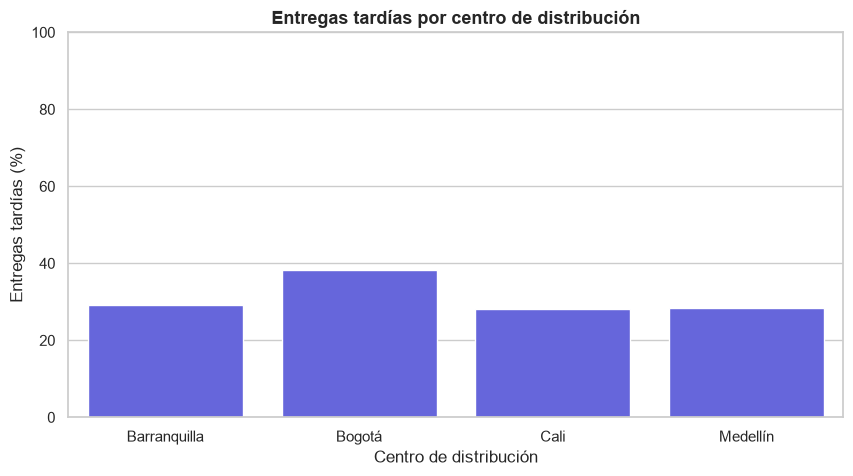

,centro_distribucion,tarde_num
0,Barranquilla,29.050279
1,Bogotá,38.198633
2,Cali,28.024558
3,Medellín,28.309305


In [13]:

tabla_centro = (
    df_eda.groupby("centro_distribucion")["tarde_num"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_centro,
    x="centro_distribucion",
    y="tarde_num",
    color="#5353EE"
)

plt.title("Entregas tardías por centro de distribución")
plt.xlabel("Centro de distribución")
plt.ylabel("Entregas tardías (%)")
plt.ylim(0, 100)
plt.show()

display(tabla_centro)


Interpretación de la gráfica 4

Bogotá presenta el mayor porcentaje de retrasos, aproximadamente el 38 %, mientras que los demás centros de distribución se encuentran alrededor del 28 % al 29 %. Esto puede indicar que las condiciones operativas de Bogotá son diferentes y requieren una revisión más detallada para identificar posibles causas de los retrasos.

Grafica 5 (Distancia recorrida y entregas tardías)

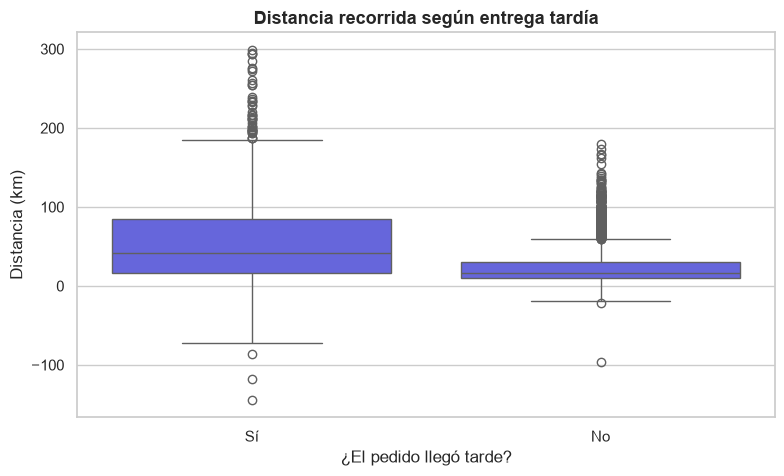

In [14]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_eda,
    x="entrega_tardia",
    y="distancia_km",
    color="#5353EE"
)

plt.title("Distancia recorrida según entrega tardía")
plt.xlabel("¿El pedido llegó tarde?")
plt.ylabel("Distancia (km)")
plt.show()


**Interpretación de la gráfica 5

La distancia recorrida presenta una relación importante con el cumplimiento de las entregas. La distribución de las distancias es diferente entre los pedidos que llegan tarde y aquellos que llegan a tiempo. Los resultados sugieren que las rutas de mayor distancia tienen un riesgo más alto de retraso. Esta variable puede ser especialmente útil para el modelo predictivo.

Grafica 6 (Numero de paradas y entregas tardías)

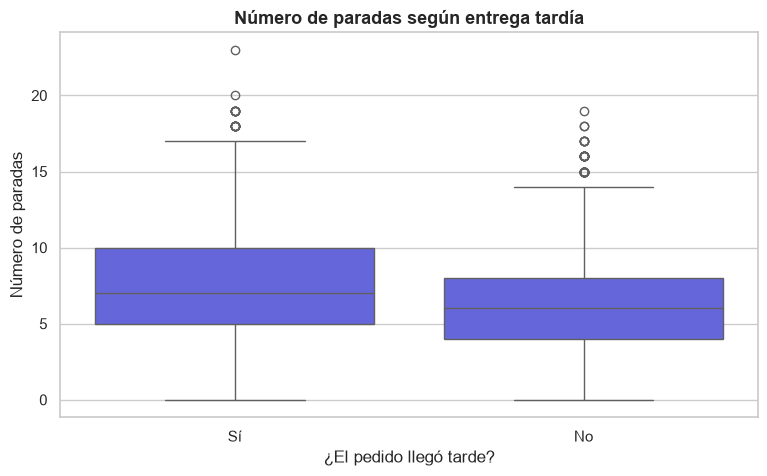

In [15]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_eda,
    x="entrega_tardia",
    y="num_paradas",
    color="#5353EE"
)

plt.title("Número de paradas según entrega tardía")
plt.xlabel("¿El pedido llegó tarde?")
plt.ylabel("Número de paradas")
plt.show()


Interpretación de la gráfica 6

El número de paradas también muestra una asociación con los retrasos. Los pedidos que llegan tarde tienden a estar vinculados con rutas que incluyen una mayor cantidad de paradas. Esto puede deberse a que cada parada añade tiempo a la operación y aumenta la posibilidad de incumplir la ventana de entrega.

Variables numericas vs entrega tarida 

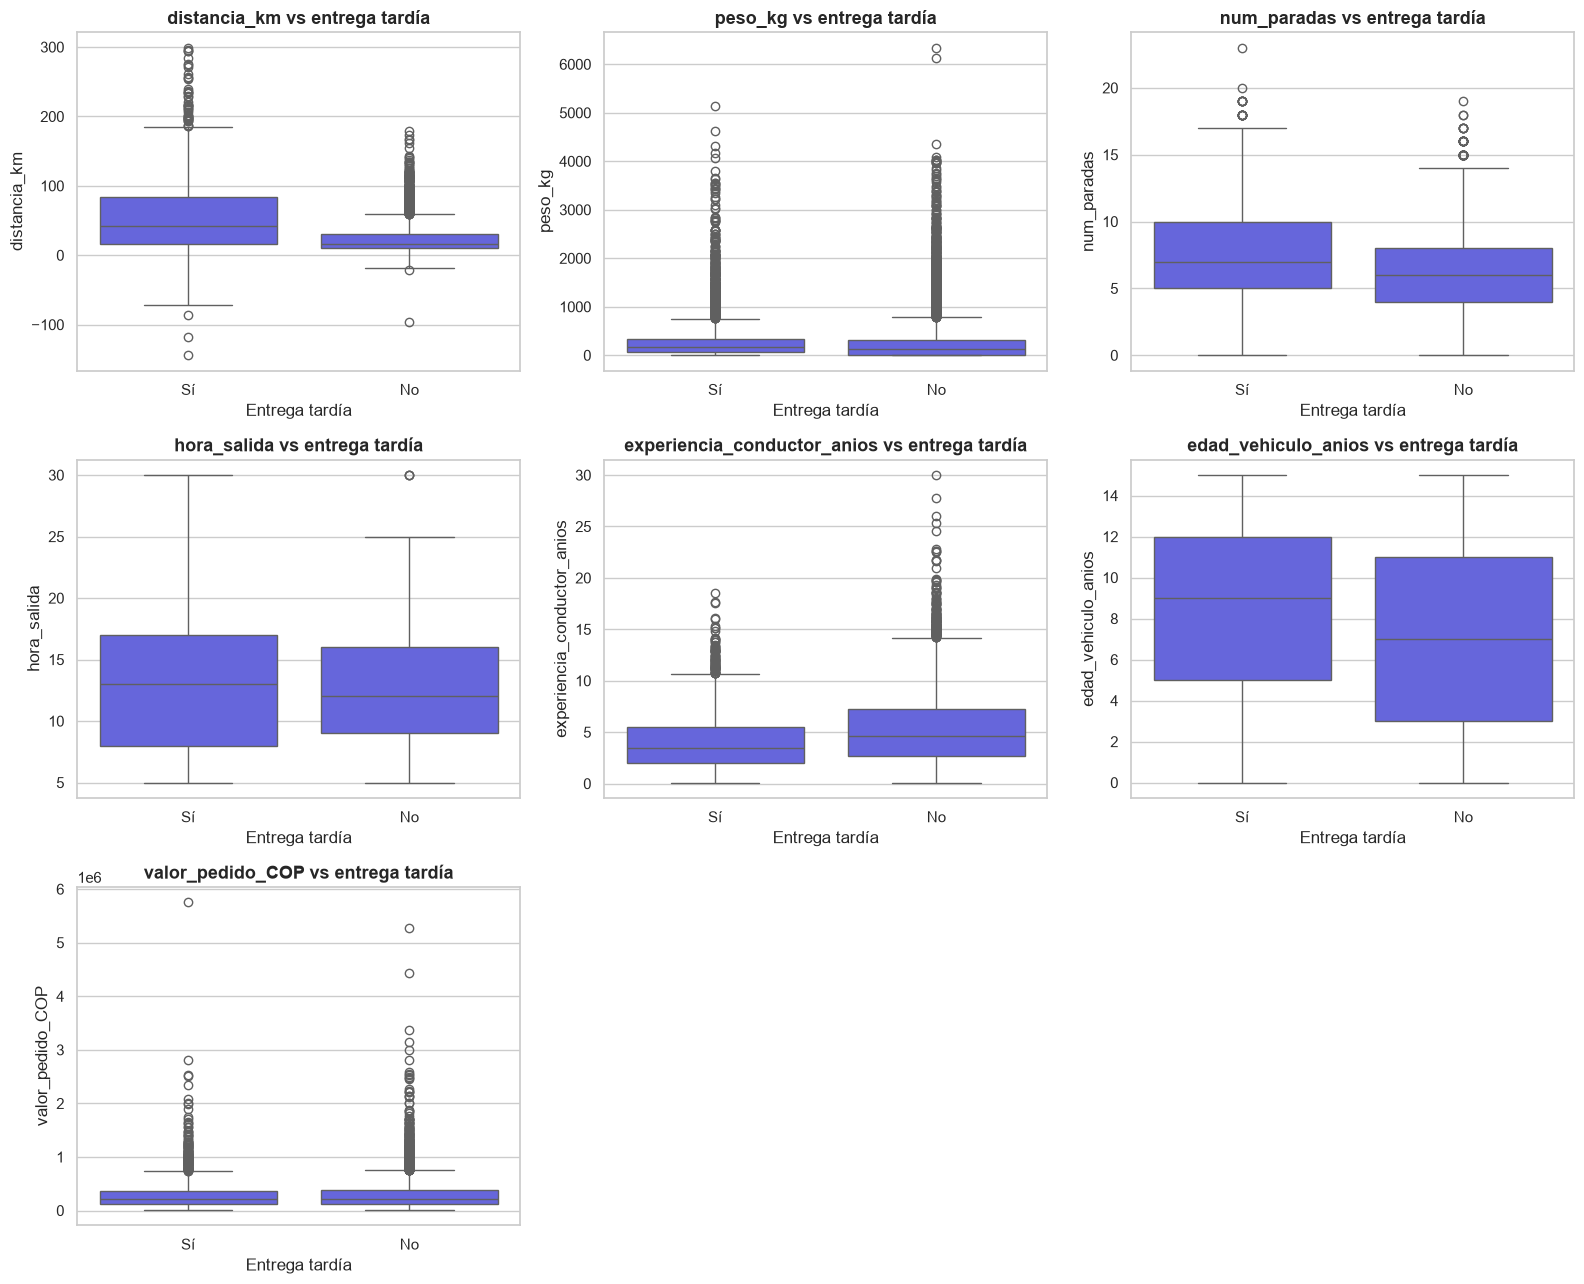

In [16]:

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, var in enumerate(variables_num):

    sns.boxplot(
        data=df_eda,
        x="entrega_tardia",
        y=var,
        color="#5353EE",
        ax=axes[i]
    )

    axes[i].set_title(f"{var} vs entrega tardía")
    axes[i].set_xlabel("Entrega tardía")
    axes[i].set_ylabel(var)

for j in range(len(variables_num), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


Interpretación variables numéricas vs entrega tardía

Al comparar las variables numéricas entre los pedidos que llegaron tarde y los que llegaron a tiempo, encontramos lo siguiente:

1. **Distancia (km):** Es la variable con la diferencia más clara. La mediana de los pedidos tardíos es de 41,6 km, mientras que la de los pedidos a tiempo es de 15,9 km. Además, los pedidos tardíos tienen muchos más valores altos, con rutas de hasta 300 km.

2. **Número de paradas:** Los pedidos que llegan tarde tienen un poco más de paradas, con una mediana de 7 frente a 6 en los pedidos a tiempo.

3. **Experiencia del conductor:** Los pedidos tardíos tienen conductores con menos experiencia, con una mediana de 3,5 años frente a 4,6 años en los pedidos a tiempo.

4. **Edad del vehículo:** Los vehículos de los pedidos tardíos son más viejos, con una mediana de 9 años frente a 7 años.

5. **Peso, hora de salida y valor del pedido:** Las cajas son muy parecidas en los dos grupos, por lo que a simple vista no muestran una relación clara con el retraso. En el caso de la hora de salida esto puede ser engañoso, porque su efecto podría no ser lineal (por ejemplo, por las horas pico).

En estas gráficas también se observan los valores imposibles que encontramos antes, como las distancias negativas y las horas de salida mayores a 23, que trataremos en la fase 3.

Variables categoricas vs entrega tardía

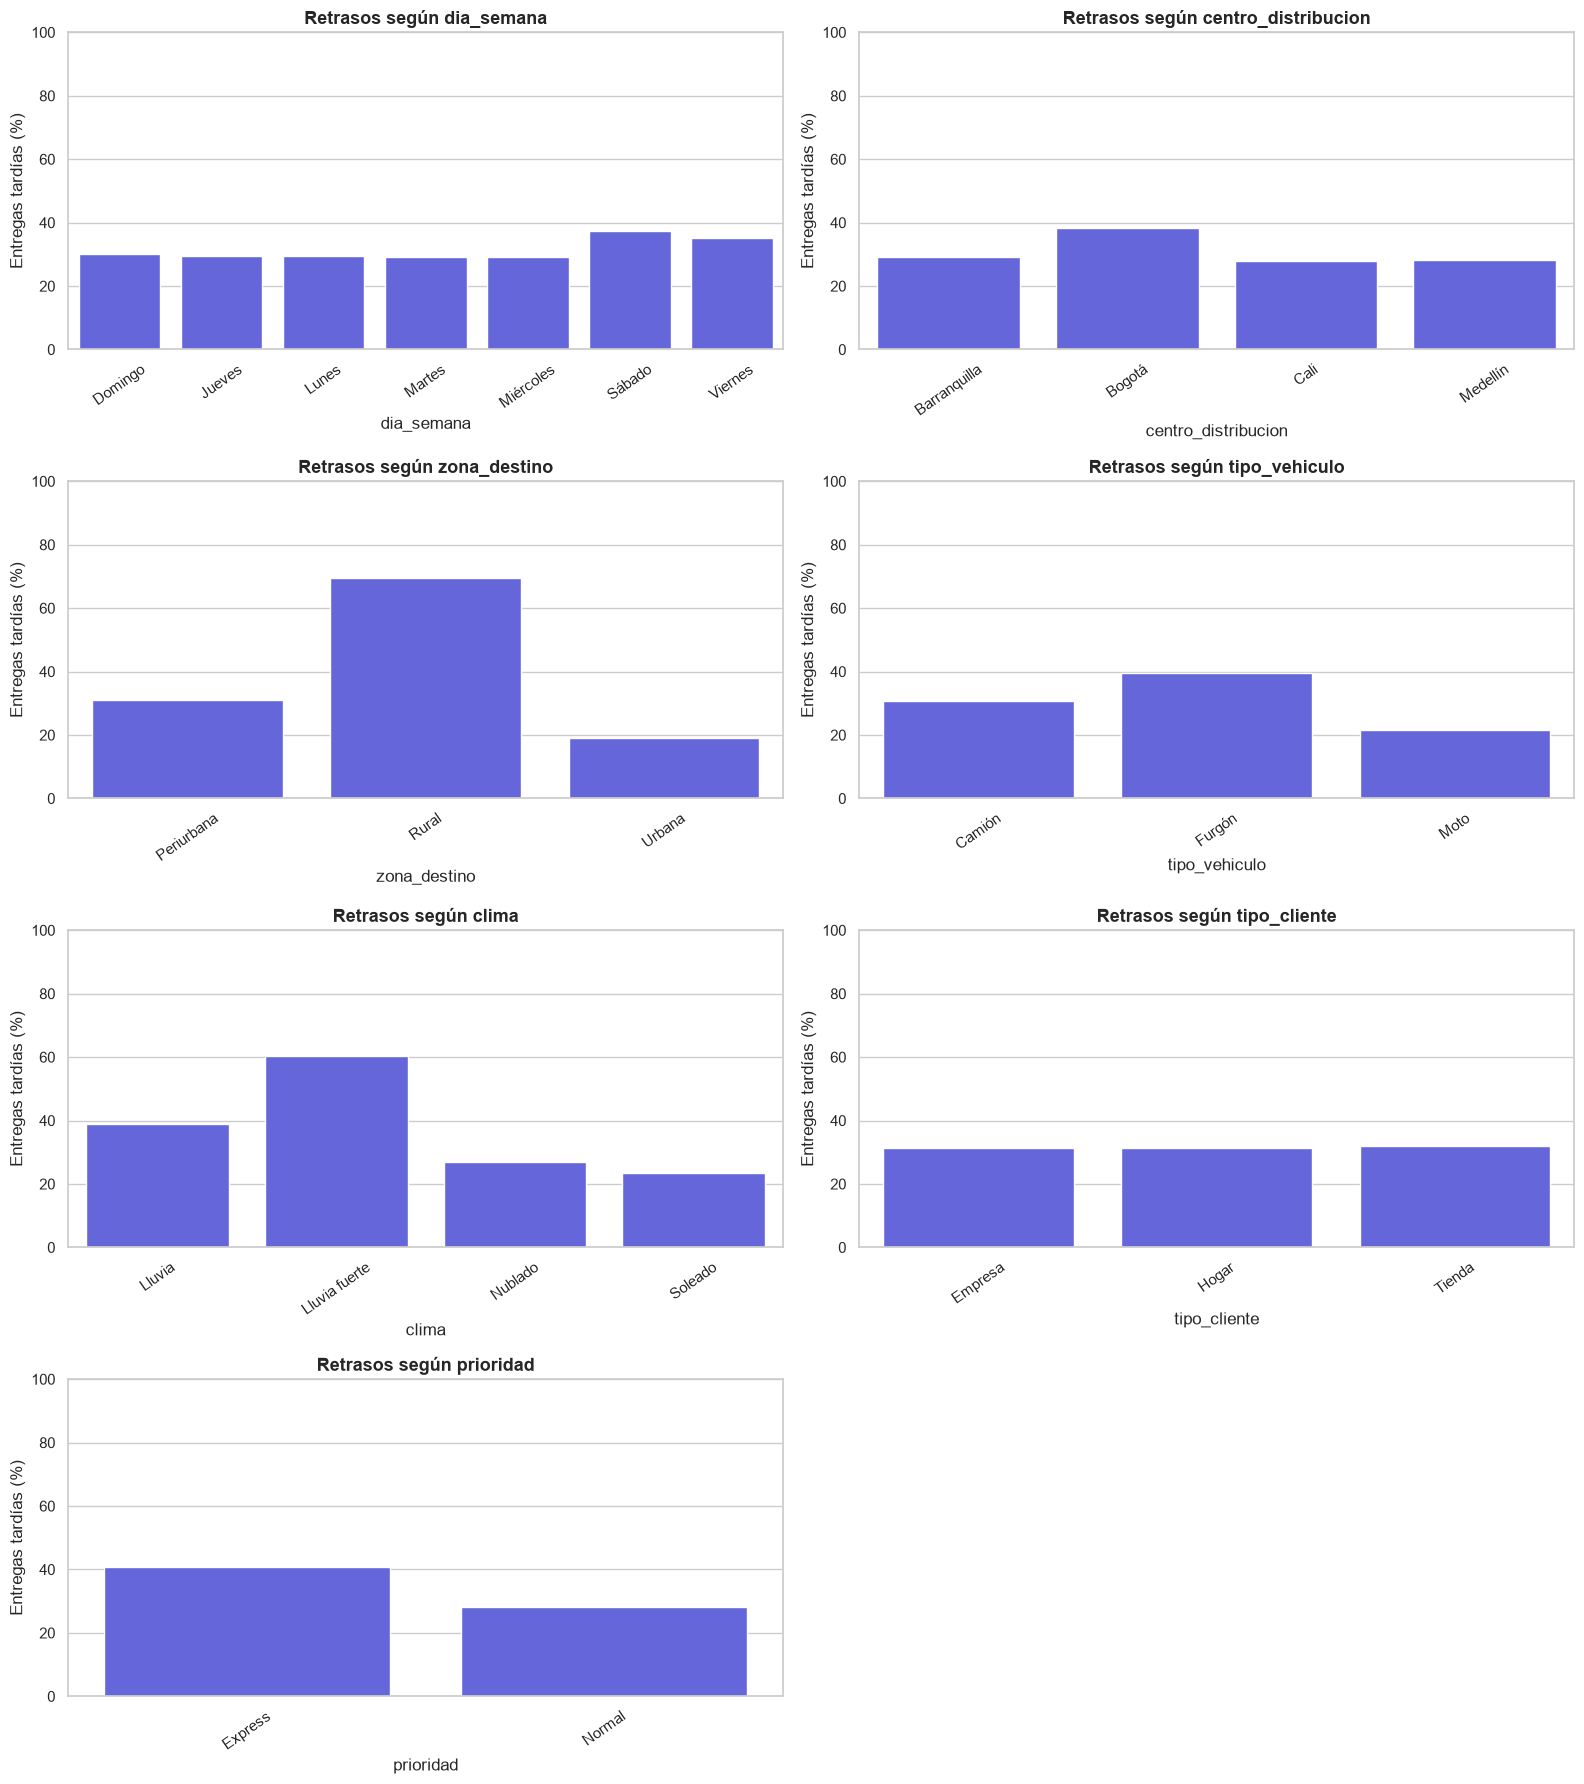

In [17]:

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, var in enumerate(variables_cat):

    tabla = (
        df_eda.groupby(var)["tarde_num"]
        .mean()
        .mul(100)
        .reset_index()
    )

    sns.barplot(
        data=tabla,
        x=var,
        y="tarde_num",
        color="#5353EE",
        ax=axes[i]
    )

    axes[i].set_title(f"Retrasos según {var}")
    axes[i].set_ylabel("Entregas tardías (%)")
    axes[i].set_xlabel(var)
    axes[i].set_ylim(0, 100)
    axes[i].tick_params(axis="x", rotation=35)

for j in range(len(variables_cat), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


Interpretación variables categóricas vs entrega tardía

Al comparar el porcentaje de entregas tardías en cada categoría, encontramos lo siguiente:

1. **Zona de destino:** Es la variable categórica con mayor diferencia. Llegan tarde el 69 % de los pedidos rurales, el 31 % de los periurbanos y el 19 % de los urbanos.

2. **Clima:** El retraso aumenta a medida que empeora el clima. Pasa de 23 % con clima soleado a 27 % con nublado, 39 % con lluvia y 60 % con lluvia fuerte.

3. **Prioridad:** Los pedidos Express llegan tarde con más frecuencia (41 %) que los pedidos normales (28 %). Esto tiene sentido, porque su ventana de entrega es más corta.

4. **Tipo de vehículo:** El furgón presenta el mayor porcentaje de retrasos (40 %), seguido del camión (31 %) y la moto (22 %).

5. **Centro de distribución:** Bogotá está por encima de los demás centros con un 38 %, mientras que los otros se encuentran entre el 28 % y el 29 %.

6. **Día de la semana:** El viernes (35 %) y el sábado (37 %) tienen más retrasos que el resto de los días, que se mantienen entre el 29 % y el 30 %.

7. **Tipo de cliente:** Casi no hay diferencia entre hogar, empresa y tienda, ya que todos están cerca del 31 %. Por eso, esta variable no parece ayudar mucho a predecir los retrasos.

En general, las variables relacionadas con la ruta y las condiciones del despacho (zona, clima, prioridad y vehículo) muestran una relación más fuerte con los retrasos que las características del cliente.

6. Punto 5 (Matríz de correlación)

,distancia_km,peso_kg,num_paradas,hora_salida,experiencia_conductor_anios,edad_vehiculo_anios,valor_pedido_COP
distancia_km,1.000000,-0.014030,0.001025,0.016615,0.008323,0.004379,-0.014554
peso_kg,-0.014030,1.000000,0.034185,0.010615,0.019609,-0.004113,-0.009414
num_paradas,0.001025,0.034185,1.000000,0.000594,-0.015356,0.015537,-0.011366
hora_salida,0.016615,0.010615,0.000594,1.000000,-0.002923,0.003860,-0.008006
experiencia_conductor_anios,0.008323,0.019609,-0.015356,-0.002923,1.000000,-0.005007,0.012059
edad_vehiculo_anios,0.004379,-0.004113,0.015537,0.003860,-0.005007,1.000000,0.000803
valor_pedido_COP,-0.014554,-0.009414,-0.011366,-0.008006,0.012059,0.000803,1.000000


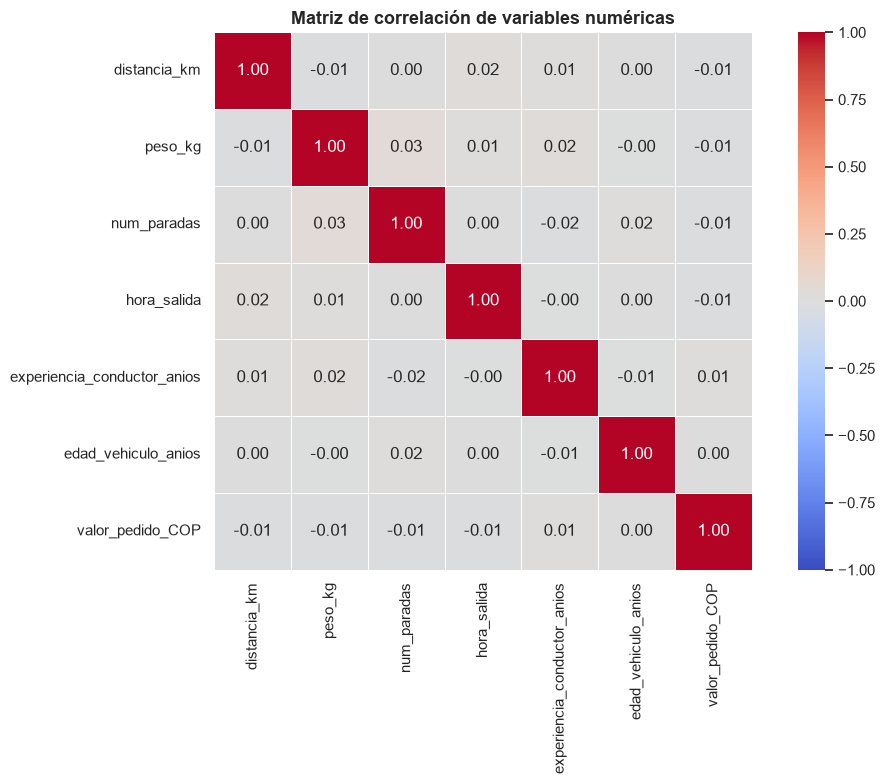

In [18]:

variables_corr = [
    "distancia_km",
    "peso_kg",
    "num_paradas",
    "hora_salida",
    "experiencia_conductor_anios",
    "edad_vehiculo_anios",
    "valor_pedido_COP"
]

matriz_corr = df_eda[variables_corr].corr()

display(matriz_corr)

plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()


Interpretación de la matriz de correlación

Al revisar la matriz, encontramos que todas las correlaciones entre las variables numéricas son muy cercanas a 0. La más alta es entre el peso y el número de paradas, y es de apenas 0,03. Esto quiere decir que las variables no están relacionadas entre sí: por ejemplo, las rutas más largas no tienen necesariamente más paradas, y los conductores con más experiencia no manejan vehículos más nuevos.

Este resultado es positivo para el modelado, porque cada variable aporta información diferente y no hay variables repetidas o redundantes. Esto es importante sobre todo para la regresión logística, ya que cuando dos variables están muy correlacionadas entre sí sus coeficientes se vuelven difíciles de interpretar.

Hay que tener en cuenta que la correlación solo mide relaciones lineales, así que una correlación cercana a 0 no descarta que exista otro tipo de relación entre las variables.

Correlación con las entregas tardías 

distancia_km                   0.413442
num_paradas                    0.220113
edad_vehiculo_anios            0.149367
hora_salida                    0.027456
peso_kg                        0.021085
valor_pedido_COP              -0.009718
experiencia_conductor_anios   -0.179203
Name: tarde_num, dtype: float64

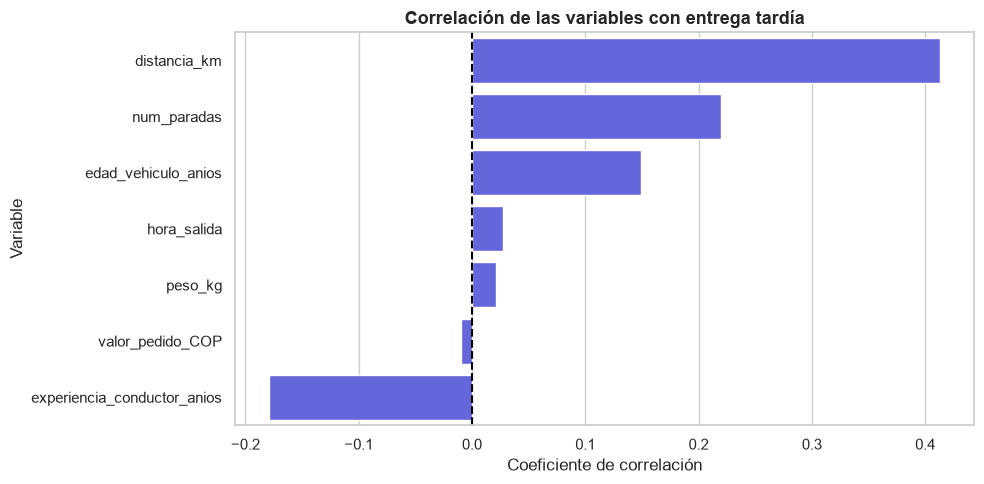

In [19]:



correlaciones_objetivo = (
    df_eda[variables_corr + ["tarde_num"]]
    .corr()["tarde_num"]
    .drop("tarde_num")
    .sort_values(ascending=False)
)

display(correlaciones_objetivo)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=correlaciones_objetivo.values,
    y=correlaciones_objetivo.index,
    color="#5353EE"
)

plt.title("Correlación de las variables con entrega tardía")
plt.xlabel("Coeficiente de correlación")
plt.ylabel("Variable")
plt.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()


Interpretación del punto 5

El análisis de correlación muestra que la distancia recorrida es la variable numérica que tiene la relación positiva más fuerte con las entregas tardías (0,41). También encontramos relaciones positivas con el número de paradas (0,22) y la edad del vehículo (0,15). Por otro lado, la experiencia del conductor presenta una correlación negativa (-0,18), lo que sugiere que los conductores con más experiencia tienden a presentar menos retrasos. Estas relaciones son útiles para identificar posibles variables predictoras, aunque una correlación no significa necesariamente que exista una relación de causa y efecto.

7. Punto 6 (Balance de clases de entrega tardías)

,Cantidad,Porcentaje (%)
entrega_tardia,,
No,5513,68.61
Sí,2522,31.39


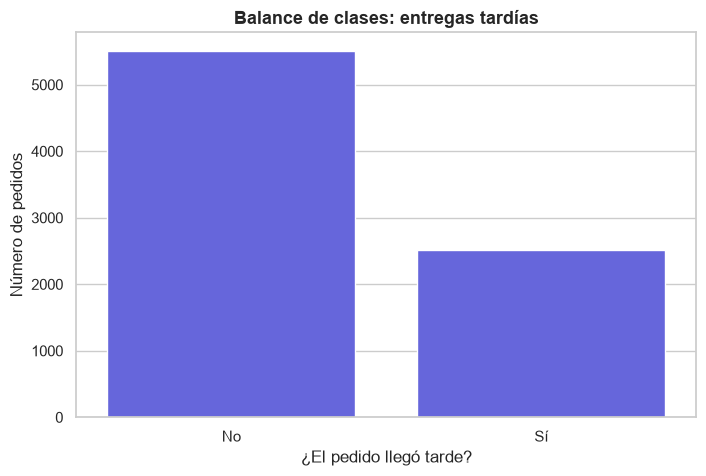

In [20]:

balance = df["entrega_tardia"].value_counts()

porcentaje_balance = (
    df["entrega_tardia"]
    .value_counts(normalize=True) * 100
)

tabla_balance = pd.DataFrame({
    "Cantidad": balance,
    "Porcentaje (%)": porcentaje_balance.round(2)
})

display(tabla_balance)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="entrega_tardia",
    order=["No", "Sí"],
    color="#5353EE"
)

plt.title("Balance de clases: entregas tardías")
plt.xlabel("¿El pedido llegó tarde?")
plt.ylabel("Número de pedidos")
plt.show()


Interpretación del punto 6

La variable objetivo presenta un desbalance moderado. El 68,61 % de los pedidos llega a tiempo, mientras que el 31,39 % llega tarde. Esto significa que hay más entregas puntuales que tardías. Este resultado es importante para la fase de modelado, porque un modelo podría obtener una exactitud relativamente alta prediciendo principalmente entregas puntuales, sin identificar correctamente los retrasos. Por eso, como establecimos en la fase 1, será importante priorizar el recall de las entregas tardías.

Conclusiones Fase 2

Después de realizar el análisis exploratorio de los datos de TransAndes, encontramos varios factores que parecen estar relacionados con las entregas tardías.

Primero, observamos que las entregas en zonas rurales tienen un porcentaje de retrasos considerablemente mayor que las urbanas. También encontramos que la lluvia fuerte está asociada con una mayor cantidad de incumplimientos.

Por otra parte, la distancia recorrida y el número de paradas muestran una relación positiva con los retrasos, mientras que la experiencia del conductor presenta una relación negativa. Esto sugiere que las características de las rutas y de los conductores pueden ser importantes para predecir las entregas tardías.

Además, identificamos problemas de calidad en la base, como valores nulos, registros duplicados, categorías inconsistentes y datos sospechosos que deben corregirse antes de entrenar los modelos.

Finalmente, encontramos que aproximadamente el 31 % de los pedidos llega tarde. Por esta razón, en las siguientes fases será importante desarrollar modelos que permitan identificar la mayor cantidad posible de retrasos reales, dando prioridad al recall de la clase "Sí".

Fase 3 (Preparación de los datos)

8. Punto 1 (Copia de la base y eliminación de duplicados)

In [21]:

df_limpio = df.copy()

print("Dimensiones antes de limpiar:", df_limpio.shape)
print("Duplicados exactos:", df_limpio.duplicated().sum())
print("Pedidos con id repetido:", df_limpio["id_pedido"].duplicated().sum())

df_limpio = df_limpio.drop_duplicates()

print("\nDimensiones después de eliminar duplicados:", df_limpio.shape)


Dimensiones antes de limpiar: (8035, 17)
Duplicados exactos: 35
Pedidos con id repetido: 35

Dimensiones después de eliminar duplicados: (8000, 17)


Interpretación del punto 1

Antes de limpiar hicimos una copia de la base original en df_limpio, para no modificar los datos originales y poder compararlos si es necesario.

Encontramos 35 registros duplicados exactos, que además tienen el mismo id_pedido. Es decir, son el mismo pedido registrado dos veces. Decidimos eliminarlos porque si los dejamos, esos pedidos tendrían el doble de peso al entrenar los modelos. Después de este paso la base quedó con 8.000 registros.

9. Punto 2 (Estandarización de categorías)

In [22]:

print("Categorías originales de centro_distribucion:")
print(df_limpio["centro_distribucion"].value_counts())
print(df_limpio["centro_distribucion"].unique())

print("\nCategorías originales de tipo_vehiculo:")
print(df_limpio["tipo_vehiculo"].value_counts())
print(df_limpio["tipo_vehiculo"].unique())


Categorías originales de centro_distribucion:
centro_distribucion
Cali            2681
Bogotá          2400
Medellín        1477
Barranquilla    1202
CALI              46
barranquilla      45
Medellin          40
BOGOTÁ            38
Bogota            37
cali              34
Name: count, dtype: int64
<StringArray>
[        'Cali',       'Bogotá',     'Medellín', 'Barranquilla',
        'CALI ',     'Medellin',         'cali',       'Bogota',
       'BOGOTÁ', 'barranquilla']
Length: 10, dtype: str

Categorías originales de tipo_vehiculo:
tipo_vehiculo
Furgón    3468
Moto      2802
Camión    1580
furgon      48
MOTO        39
Camion      32
Furgon      31
Name: count, dtype: int64
<StringArray>
['Furgón', 'Moto', 'Camión', 'MOTO', 'furgon', 'Furgon', 'Camion']
Length: 7, dtype: str


In [23]:

df_limpio["centro_distribucion"] = (
    df_limpio["centro_distribucion"]
    .str.strip()
    .str.lower()
    .replace({
        "bogota": "bogotá",
        "medellin": "medellín"
    })
    .str.title()
)

df_limpio["tipo_vehiculo"] = (
    df_limpio["tipo_vehiculo"]
    .str.strip()
    .str.lower()
    .replace({
        "furgon": "furgón",
        "camion": "camión"
    })
    .str.title()
)

for var in variables_cat:
    print(var, "->", df_limpio[var].dropna().unique().tolist())


dia_semana -> ['Viernes', 'Miércoles', 'Domingo', 'Martes', 'Sábado', 'Lunes', 'Jueves']
centro_distribucion -> ['Cali', 'Bogotá', 'Medellín', 'Barranquilla']
zona_destino -> ['Rural', 'Urbana', 'Periurbana']
tipo_vehiculo -> ['Furgón', 'Moto', 'Camión']
clima -> ['Lluvia', 'Soleado', 'Nublado', 'Lluvia fuerte']
tipo_cliente -> ['Empresa', 'Hogar', 'Tienda']
prioridad -> ['Normal', 'Express']


Interpretación del punto 2

En la variable centro_distribucion había 10 formas distintas de escribir solo 4 ciudades, por ejemplo "CALI " con un espacio al final, "cali", "Bogota" sin tilde o "BOGOTÁ" en mayúscula. En tipo_vehiculo pasaba lo mismo, con 7 formas de escribir 3 vehículos ("furgon", "Furgon", "MOTO" y "Camion").

Para corregirlo quitamos los espacios con strip(), pasamos todo a minúscula, unificamos las tildes y dejamos la primera letra en mayúscula con title(). Así quedaron 4 centros de distribución y 3 tipos de vehículo. Las demás variables categóricas ya estaban bien escritas, por eso no fue necesario cambiarlas.

10. Punto 3 (Valores imposibles o sospechosos)

In [24]:

tabla_imposibles = pd.DataFrame({
    "Problema": [
        "Distancia negativa",
        "Hora de salida mayor a 23",
        "Peso igual a 0",
        "Número de paradas igual a 0"
    ],
    "Cantidad de registros": [
        (df_limpio["distancia_km"] < 0).sum(),
        (df_limpio["hora_salida"] > 23).sum(),
        (df_limpio["peso_kg"] == 0).sum(),
        (df_limpio["num_paradas"] == 0).sum()
    ]
})

display(tabla_imposibles)

print("Distancias negativas:")
print(df_limpio.loc[df_limpio["distancia_km"] < 0, ["zona_destino", "distancia_km"]].head(10))

print("\nHoras de salida fuera de rango:")
print(df_limpio.loc[df_limpio["hora_salida"] > 23, "hora_salida"].value_counts())


,Problema,Cantidad de registros
0,Distancia negativa,20
1,Hora de salida mayor a 23,10
2,Peso igual a 0,15
3,Número de paradas igual a 0,59


Distancias negativas:
     zona_destino  distancia_km
367    Periurbana         -86.3
805        Urbana         -15.1
1538       Urbana         -16.5
1633       Urbana         -11.9
1813       Urbana         -16.1
3506        Rural         -96.6
3688       Urbana         -14.9
3754       Urbana         -12.8
3769       Urbana         -14.4
3982        Rural        -118.1

Horas de salida fuera de rango:
hora_salida
25.0    6
30.0    4
Name: count, dtype: int64


Revisión de valores extremos

In [25]:

print("Experiencia máxima del conductor:", df_limpio["experiencia_conductor_anios"].max())
print("Vehículos con 0 años de antigüedad:", (df_limpio["edad_vehiculo_anios"] == 0).sum())
print("Valor máximo de un pedido (COP):", df_limpio["valor_pedido_COP"].max())
print("Distancia máxima (km):", df_limpio["distancia_km"].max())

print("\nPeso de los pedidos según tipo de vehículo:")
display(df_limpio.groupby("tipo_vehiculo")["peso_kg"].describe(percentiles=[0.5, 0.99]).round(1))

print(
    "Motos con más de 100 kg:",
    ((df_limpio["tipo_vehiculo"] == "Moto") & (df_limpio["peso_kg"] > 100)).sum()
)


Experiencia máxima del conductor: 30.0
Vehículos con 0 años de antigüedad: 466
Valor máximo de un pedido (COP): 5752400.0
Distancia máxima (km): 299.0

Peso de los pedidos según tipo de vehículo:


,count,mean,std,min,50%,99%,max
tipo_vehiculo,,,,,,,
Camión,1482.0,1359.8,761.1,0.0,1205.7,3967.5,6341.2
Furgón,3266.0,206.0,131.9,0.0,180.4,623.7,2166.7
Moto,2612.0,14.3,71.1,0.0,8.0,47.9,1914.6


Motos con más de 100 kg: 25


Corrección de los valores imposibles

In [26]:

df_limpio["distancia_km"] = df_limpio["distancia_km"].abs()

df_limpio.loc[df_limpio["hora_salida"] > 23, "hora_salida"] = np.nan
df_limpio.loc[df_limpio["peso_kg"] == 0, "peso_kg"] = np.nan
df_limpio.loc[df_limpio["num_paradas"] == 0, "num_paradas"] = np.nan

print("Distancias negativas:", (df_limpio["distancia_km"] < 0).sum())
print("Horas mayores a 23:", (df_limpio["hora_salida"] > 23).sum())
print("Pesos iguales a 0:", (df_limpio["peso_kg"] == 0).sum())
print("Rutas con 0 paradas:", (df_limpio["num_paradas"] == 0).sum())


Distancias negativas: 0
Horas mayores a 23: 0
Pesos iguales a 0: 0
Rutas con 0 paradas: 0


Interpretación del punto 3

Encontramos cuatro tipos de valores imposibles y tomamos una decisión para cada uno:

1. **Distancias negativas (20 registros):** Una distancia no puede ser negativa. Al revisar estos casos vimos que, sin el signo, los valores son normales para su zona (por ejemplo, -15,1 km en una zona urbana). Por eso creemos que es un error de signo y los convertimos a positivo con abs(), en lugar de eliminarlos.

2. **Horas de salida mayores a 23 (10 registros):** Hay 6 pedidos con hora 25 y 4 con hora 30, y esas horas no existen. Como no sabemos cuál era la hora real, los convertimos a nulo para tratarlos en el punto 4.

3. **Peso igual a 0 (15 registros):** Un pedido no puede pesar 0 kg, así que lo tomamos como un error de registro y lo convertimos a nulo.

4. **Número de paradas igual a 0 (59 registros):** Si el vehículo entregó el pedido, la ruta tuvo por lo menos una parada. Por eso también los convertimos a nulo.

También revisamos valores extremos que son posibles y decidimos dejarlos. Una experiencia de 30 años puede ser un conductor con mucha trayectoria. Los 466 vehículos con 0 años son vehículos nuevos. Un pedido de 5,75 millones de pesos puede ser una compra grande, y rutas de hasta 299 km son normales en zonas rurales.

Por último, encontramos 25 motos con pedidos de más de 100 kg, cuando el 99 % de las motos lleva menos de 48 kg. Estos casos son raros, pero decidimos dejarlos porque no tenemos forma de confirmar que sean errores y representan menos del 1 % de los pedidos en moto.

11. Punto 4 (Tratamiento de valores nulos)

In [27]:

nulos_limpio = df_limpio.isna().sum()

tabla_nulos_limpio = pd.DataFrame({
    "Cantidad de nulos": nulos_limpio,
    "Porcentaje (%)": (df_limpio.isna().mean() * 100).round(2)
})

tabla_nulos_limpio = tabla_nulos_limpio[tabla_nulos_limpio["Cantidad de nulos"] > 0]
tabla_nulos_limpio = tabla_nulos_limpio.sort_values("Porcentaje (%)", ascending=False)

display(tabla_nulos_limpio)

filas_con_nulos = df_limpio.isna().any(axis=1).sum()

print("Filas con al menos un nulo:", filas_con_nulos)
print("Porcentaje de la base:", round(filas_con_nulos / len(df_limpio) * 100, 2), "%")


,Cantidad de nulos,Porcentaje (%)
experiencia_conductor_anios,880,11.00
clima,720,9.00
peso_kg,655,8.19
edad_vehiculo_anios,560,7.00
num_paradas,539,6.74
distancia_km,400,5.00
valor_pedido_COP,400,5.00
hora_salida,330,4.12
tipo_cliente,240,3.00


Filas con al menos un nulo: 3617
Porcentaje de la base: 45.21 %


Relación de los nulos con la variable objetivo

In [28]:

tarde = df_limpio["entrega_tardia"].map({"Sí": 1, "No": 0})

comparacion_nulos = []

for var in tabla_nulos_limpio.index:
    comparacion_nulos.append({
        "Variable": var,
        "% tardías con nulo": round(tarde[df_limpio[var].isna()].mean() * 100, 2),
        "% tardías sin nulo": round(tarde[df_limpio[var].notna()].mean() * 100, 2)
    })

comparacion_nulos = pd.DataFrame(comparacion_nulos)

display(comparacion_nulos)


,Variable,% tardías con nulo,% tardías sin nulo
0,experiencia_conductor_anios,32.16,31.24
1,clima,29.72,31.50
2,peso_kg,30.84,31.38
3,edad_vehiculo_anios,32.32,31.26
4,num_paradas,31.73,31.31
5,distancia_km,30.75,31.37
6,valor_pedido_COP,31.50,31.33
7,hora_salida,29.70,31.41
8,tipo_cliente,30.00,31.38


Medidas para decidir cómo imputar

In [29]:

tabla_medidas = pd.DataFrame({
    "Media": df_limpio[variables_num].mean().round(2),
    "Mediana": df_limpio[variables_num].median(),
    "Asimetría": df_limpio[variables_num].skew().round(2)
})

display(tabla_medidas)

print("Mediana del peso según tipo de vehículo:")
print(df_limpio.groupby("tipo_vehiculo")["peso_kg"].median())

print("\nMediana de la distancia según zona de destino:")
print(df_limpio.groupby("zona_destino")["distancia_km"].median())


,Media,Mediana,Asimetría
distancia_km,34.39,19.5,2.27
peso_kg,371.06,143.7,2.83
num_paradas,6.61,6.0,0.56
hora_salida,12.51,12.0,-0.01
experiencia_conductor_anios,4.98,4.2,1.36
edad_vehiculo_anios,7.36,7.0,0.03
valor_pedido_COP,301391.92,215900.0,4.41


Mediana del peso según tipo de vehículo:
tipo_vehiculo
Camión    1207.40
Furgón     180.65
Moto         8.10
Name: peso_kg, dtype: float64

Mediana de la distancia según zona de destino:
zona_destino
Periurbana    34.40
Rural         85.95
Urbana        11.80
Name: distancia_km, dtype: float64


Estrategia para los nulos

Después de convertir los valores imposibles a nulo, 3.617 filas (45,21 % de la base) tienen al menos un dato faltante. Si elimináramos esas filas perderíamos casi la mitad de la información, por eso decidimos imputar en lugar de eliminar.

Además, en la tabla de nulos contra la variable objetivo vemos que el porcentaje de entregas tardías es muy parecido en las filas con nulo y sin nulo (entre 29,7 % y 32,3 %, frente a cerca de 31 %). Esto indica que los nulos no parecen estar relacionados con los retrasos, entonces imputarlos no debería cambiar mucho los resultados.

La estrategia para cada columna fue:

1. **Experiencia del conductor (11 %):** Mediana (4,2 años). La distribución es asimétrica (1,36), por lo que la media se ve afectada por los pocos conductores con muchos años de experiencia.

2. **Clima (9 %):** Creamos la categoría "Sin dato". Si usáramos la moda (Soleado), estaríamos diciendo que 720 pedidos tuvieron sol sin saberlo, y en el EDA vimos que el clima influye mucho en los retrasos.

3. **Peso (8,19 %):** Mediana según el tipo de vehículo. La mediana general (143,7 kg) sería demasiado para una moto y muy poco para un camión. Por eso usamos 8,1 kg para motos, 180,65 kg para furgones y 1.207,4 kg para camiones.

4. **Edad del vehículo (7 %):** Mediana (7 años). En esta variable la media y la mediana son casi iguales porque la distribución es simétrica.

5. **Número de paradas (6,74 %):** Mediana (6 paradas).

6. **Distancia (5 %):** Mediana según la zona de destino, porque la distancia cambia mucho entre zonas: 11,8 km en urbana, 34,4 km en periurbana y 85,95 km en rural.

7. **Valor del pedido (5 %):** Mediana (215.900 pesos). Es la variable más asimétrica (4,41), por lo que la media no representa bien un pedido normal.

8. **Hora de salida (4,12 %):** Mediana (12 horas).

9. **Tipo de cliente (3 %):** Moda (Hogar). Son pocos nulos y en el EDA vimos que esta variable casi no influye en los retrasos.

In [30]:

df_limpio["peso_kg"] = df_limpio["peso_kg"].fillna(
    df_limpio.groupby("tipo_vehiculo")["peso_kg"].transform("median")
)

df_limpio["distancia_km"] = df_limpio["distancia_km"].fillna(
    df_limpio.groupby("zona_destino")["distancia_km"].transform("median")
)

variables_mediana = [
    "num_paradas",
    "hora_salida",
    "experiencia_conductor_anios",
    "edad_vehiculo_anios",
    "valor_pedido_COP"
]

for var in variables_mediana:
    df_limpio[var] = df_limpio[var].fillna(df_limpio[var].median())

df_limpio["clima"] = df_limpio["clima"].fillna("Sin dato")

df_limpio["tipo_cliente"] = df_limpio["tipo_cliente"].fillna(
    df_limpio["tipo_cliente"].mode()[0]
)

print("Nulos después del tratamiento:")
print(df_limpio.isna().sum())


Nulos después del tratamiento:
id_pedido                      0
fecha_despacho                 0
dia_semana                     0
centro_distribucion            0
zona_destino                   0
tipo_vehiculo                  0
distancia_km                   0
peso_kg                        0
num_paradas                    0
hora_salida                    0
clima                          0
experiencia_conductor_anios    0
edad_vehiculo_anios            0
tipo_cliente                   0
prioridad                      0
valor_pedido_COP               0
entrega_tardia                 0
dtype: int64


Interpretación del punto 4

Después de aplicar la estrategia comprobamos que ya no quedan valores nulos en ninguna columna y que la base conserva sus 8.000 registros.

12. Punto 5 (Nueva variable: hora pico)

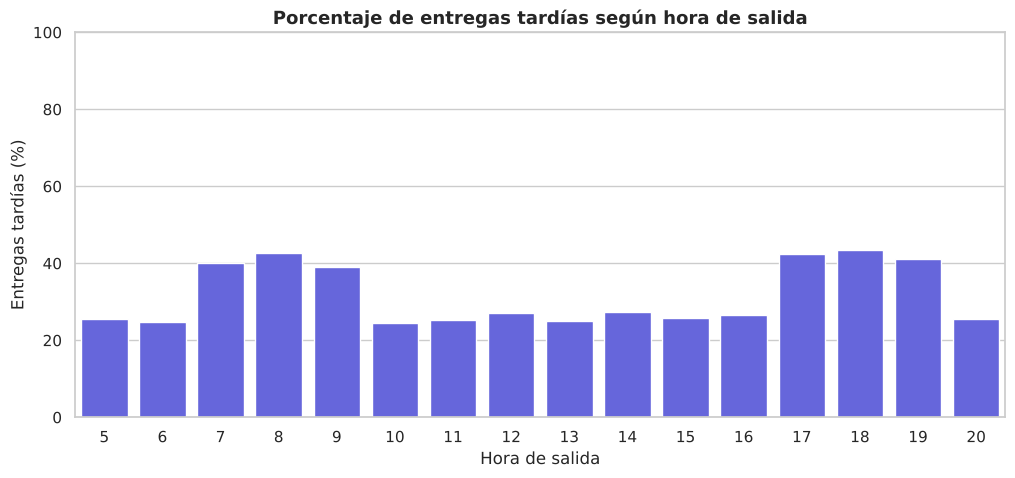

,hora_salida,tarde_num
0,5,25.60
1,6,24.84
2,7,39.96
3,8,42.56
4,9,39.00
5,10,24.43
6,11,25.20
7,12,27.13
8,13,24.90
9,14,27.35


In [31]:

df_hora = pd.DataFrame({
    "hora_salida": df_limpio["hora_salida"].astype(int),
    "tarde_num": tarde
})

tabla_hora = (
    df_hora.groupby("hora_salida")["tarde_num"]
    .mean()
    .mul(100)
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=tabla_hora,
    x="hora_salida",
    y="tarde_num",
    color="#5353EE"
)

plt.title("Porcentaje de entregas tardías según hora de salida")
plt.xlabel("Hora de salida")
plt.ylabel("Entregas tardías (%)")
plt.ylim(0, 100)
plt.show()

display(tabla_hora.round(2))


In [32]:

horas_pico = [7, 8, 9, 17, 18, 19]

df_limpio["hora_pico"] = df_limpio["hora_salida"].isin(horas_pico).astype(int)

print("Pedidos según hora pico (1 = sí, 0 = no):")
print(df_limpio["hora_pico"].value_counts())

print("\nPorcentaje de entregas tardías según hora pico:")
print(tarde.groupby(df_limpio["hora_pico"]).mean().mul(100).round(2))


Pedidos según hora pico (1 = sí, 0 = no):
hora_pico
0    5195
1    2805
Name: count, dtype: int64

Porcentaje de entregas tardías según hora pico:
hora_pico
0    25.85
1    41.50
Name: entrega_tardia, dtype: float64


Interpretación del punto 5

En el EDA la correlación entre la hora de salida y las entregas tardías fue casi 0 (0,03), pero esta gráfica muestra que la hora sí importa. Cuando el vehículo sale entre las 7 y las 9 de la mañana o entre las 17 y las 19 horas, el porcentaje de retrasos sube a valores entre 39 % y 44 %. En el resto del día se mantiene entre 24 % y 27 %. Como el retraso sube y baja en dos momentos del día, la relación no es lineal y por eso la correlación no la detecta.

Por esta razón creamos la variable hora_pico, que vale 1 si el pedido sale en una de esas horas y 0 si no. Los pedidos que salen en hora pico llegan tarde el 41,5 % de las veces, frente a 25,85 % de los que salen en otras horas. Esta variable le sirve sobre todo a la regresión logística, que solo capta relaciones lineales. El árbol de decisión podría encontrar estos cortes por sí solo, pero tenerla también le facilita el trabajo.

13. Punto 6 (Base limpia y codificación de variables categóricas)

In [33]:

df_limpio.to_csv("logistica_entregas_limpia.csv", index=False)

print("Base limpia guardada:", df_limpio.shape)
df_limpio.head()


Base limpia guardada: (8000, 18)


,id_pedido,fecha_despacho,dia_semana,centro_distribucion,zona_destino,tipo_vehiculo,distancia_km,peso_kg,num_paradas,hora_salida,clima,experiencia_conductor_anios,edad_vehiculo_anios,tipo_cliente,prioridad,valor_pedido_COP,entrega_tardia,hora_pico
0,P-04180,2025-10-24,Viernes,Cali,Rural,Furgón,58.9,115.5,10.0,19.0,Lluvia,5.7,9.0,Empresa,Normal,193700.0,Sí,1
1,P-00296,2025-11-19,Miércoles,Bogotá,Urbana,Furgón,25.7,264.3,6.0,17.0,Lluvia,3.2,4.0,Hogar,Normal,361300.0,Sí,1
2,P-02789,2025-02-23,Domingo,Medellín,Urbana,Moto,18.6,8.1,7.0,20.0,Soleado,4.2,5.0,Hogar,Express,170600.0,No,0
3,P-01284,2025-01-21,Martes,Bogotá,Urbana,Moto,5.1,9.2,1.0,6.0,Soleado,10.2,5.0,Empresa,Normal,622400.0,No,0
4,P-05152,2025-07-12,Sábado,Bogotá,Urbana,Furgón,14.2,260.5,1.0,5.0,Lluvia,6.5,15.0,Hogar,Normal,406500.0,No,0


In [34]:

y = df_limpio["entrega_tardia"].map({"Sí": 1, "No": 0})

X = df_limpio.drop(columns=["id_pedido", "fecha_despacho", "entrega_tardia"])

X = pd.get_dummies(
    X,
    columns=variables_cat,
    drop_first=True,
    dtype=int
)

print("Dimensiones de X:", X.shape)
print("\nColumnas del modelo:")
print(X.columns.tolist())


Dimensiones de X: (8000, 28)

Columnas del modelo:
['distancia_km', 'peso_kg', 'num_paradas', 'hora_salida', 'experiencia_conductor_anios', 'edad_vehiculo_anios', 'valor_pedido_COP', 'hora_pico', 'dia_semana_Jueves', 'dia_semana_Lunes', 'dia_semana_Martes', 'dia_semana_Miércoles', 'dia_semana_Sábado', 'dia_semana_Viernes', 'centro_distribucion_Bogotá', 'centro_distribucion_Cali', 'centro_distribucion_Medellín', 'zona_destino_Rural', 'zona_destino_Urbana', 'tipo_vehiculo_Furgón', 'tipo_vehiculo_Moto', 'clima_Lluvia fuerte', 'clima_Nublado', 'clima_Sin dato', 'clima_Soleado', 'tipo_cliente_Hogar', 'tipo_cliente_Tienda', 'prioridad_Normal']


Interpretación del punto 6

Guardamos la base limpia en el archivo logistica_entregas_limpia.csv, con 8.000 registros y 18 columnas (las 17 originales más hora_pico). Esta es la base que usamos para modelar.

Para preparar los datos del modelo convertimos la variable objetivo en números (1 si llegó tarde y 0 si llegó a tiempo). También quitamos id_pedido, porque es solo un identificador y no ayuda a predecir, y fecha_despacho, porque la información útil de la fecha ya está en dia_semana.

Las variables categóricas las convertimos con get_dummies, que crea una columna de 0 y 1 por cada categoría. Usamos drop_first=True para eliminar una categoría de cada variable, porque si todas las demás columnas valen 0 ya se sabe que el pedido pertenece a esa categoría. Las categorías que quedaron como referencia son Domingo, Barranquilla, Periurbana, Camión, Lluvia, Empresa y Express. Al final quedaron 28 variables para el modelo.

14. Punto 7 (División en entrenamiento y prueba y escalado)

In [35]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nProporción de entregas tardías en entrenamiento:", round(y_train.mean() * 100, 2), "%")
print("Proporción de entregas tardías en prueba:", round(y_test.mean() * 100, 2), "%")


Entrenamiento: (5600, 28)
Prueba: (2400, 28)

Proporción de entregas tardías en entrenamiento: 31.34 %
Proporción de entregas tardías en prueba: 31.33 %


In [36]:

from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()

X_train_esc = pd.DataFrame(
    escalador.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_esc = pd.DataFrame(
    escalador.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

tabla_escalado = pd.DataFrame({
    "Media": X_train_esc[variables_num].mean().round(2).abs(),
    "Desviación estándar": X_train_esc[variables_num].std().round(2)
})

display(tabla_escalado)


,Media,Desviación estándar
distancia_km,0.0,1.0
peso_kg,0.0,1.0
num_paradas,0.0,1.0
hora_salida,0.0,1.0
experiencia_conductor_anios,0.0,1.0
edad_vehiculo_anios,0.0,1.0
valor_pedido_COP,0.0,1.0


Interpretación del punto 7

Dividimos la base en 70 % para entrenamiento (5.600 pedidos) y 30 % para prueba (2.400 pedidos), usando stratify=y y random_state=42. Gracias a stratify, la proporción de entregas tardías es casi igual en los dos conjuntos (31,34 % y 31,33 %), así que ambos representan bien la base completa.

Los modelos que vamos a usar son la regresión logística y el árbol de decisión. La regresión logística necesita variables escaladas porque las variables tienen escalas muy diferentes, por ejemplo el valor del pedido está en cientos de miles de pesos mientras que el número de paradas va de 1 a 23. Con StandardScaler cada variable queda con media 0 y desviación estándar 1. El escalador se ajustó solo con los datos de entrenamiento y después se aplicó a los de prueba, para que el modelo no use información del conjunto de prueba.

El árbol de decisión no necesita escalado porque divide los datos usando umbrales, así que para el árbol usaremos X_train y X_test sin escalar, y para la regresión logística usaremos X_train_esc y X_test_esc.

Conclusiones Fase 3

En esta fase dejamos la base lista para entrenar los modelos. Eliminamos 35 registros duplicados y corregimos las categorías mal escritas en centro_distribucion y tipo_vehiculo. También encontramos valores imposibles: corregimos las distancias negativas como errores de signo y convertimos a nulo las horas mayores a 23, los pesos iguales a 0 y las rutas con 0 paradas.

Para los nulos decidimos imputar en lugar de eliminar filas, porque perderíamos casi la mitad de la base y los nulos no parecen estar relacionados con los retrasos. Usamos la mediana en las variables numéricas (por grupo en el peso y la distancia), una categoría "Sin dato" en el clima y la moda en el tipo de cliente.

Además creamos la variable hora_pico, porque encontramos que el efecto de la hora de salida no es lineal. Finalmente codificamos las variables categóricas, dividimos la base en 70 % y 30 % y escalamos los datos para la regresión logística. La base limpia quedó con 8.000 registros y sin valores nulos.

Fase 4 (Modelado)

15. Punto 1 (Regresión logística: prueba de configuraciones)

In [37]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

valores_C = [1, 0.01, 0.001]

resultados_log = []

for c in valores_C:

    modelo = LogisticRegression(C=c, max_iter=1000)
    modelo.fit(X_train_esc, y_train)

    pred_train = modelo.predict(X_train_esc)
    pred_test = modelo.predict(X_test_esc)

    resultados_log.append({
        "C": c,
        "Accuracy entrenamiento": round(accuracy_score(y_train, pred_train), 3),
        "Accuracy prueba": round(accuracy_score(y_test, pred_test), 3),
        "Recall prueba": round(recall_score(y_test, pred_test), 3),
        "F1 prueba": round(f1_score(y_test, pred_test), 3)
    })

resultados_log = pd.DataFrame(resultados_log)

display(resultados_log)


,C,Accuracy entrenamiento,Accuracy prueba,Recall prueba,F1 prueba
0,1.000,0.829,0.820,0.630,0.687
1,0.010,0.826,0.823,0.604,0.682
2,0.001,0.806,0.801,0.441,0.582


Interpretación del punto 1

En la regresión logística probamos tres valores del hiperparámetro C, que controla la regularización. Entre más pequeño es C, más se "castigan" los coeficientes grandes y el modelo se vuelve más simple.

Con C = 1 y C = 0,01 los resultados son muy parecidos, pero C = 1 detecta más entregas tardías, con un recall de 0,630 frente a 0,604, y tiene el mejor F1 (0,687). Con C = 0,001 el modelo se vuelve demasiado simple y el recall baja a 0,441, es decir, deja de detectar más de la mitad de los retrasos.

En ninguna de las tres configuraciones hay sobreajuste, porque el accuracy de entrenamiento y el de prueba son casi iguales (por ejemplo, 0,829 y 0,820 con C = 1).

Por eso elegimos **C = 1**, ya que en la fase 1 definimos que lo más importante es detectar la mayor cantidad posible de pedidos que van a llegar tarde.

16. Punto 2 (Regresión logística: modelo elegido y coeficientes)

,Variable,Coeficiente
0,distancia_km,1.190
2,num_paradas,0.603
5,edad_vehiculo_anios,0.588
7,hora_pico,0.582
21,clima_Lluvia fuerte,0.453
14,centro_distribucion_Bogotá,0.319
17,zona_destino_Rural,0.319
12,dia_semana_Sábado,0.247
13,dia_semana_Viernes,0.240
10,dia_semana_Martes,0.065


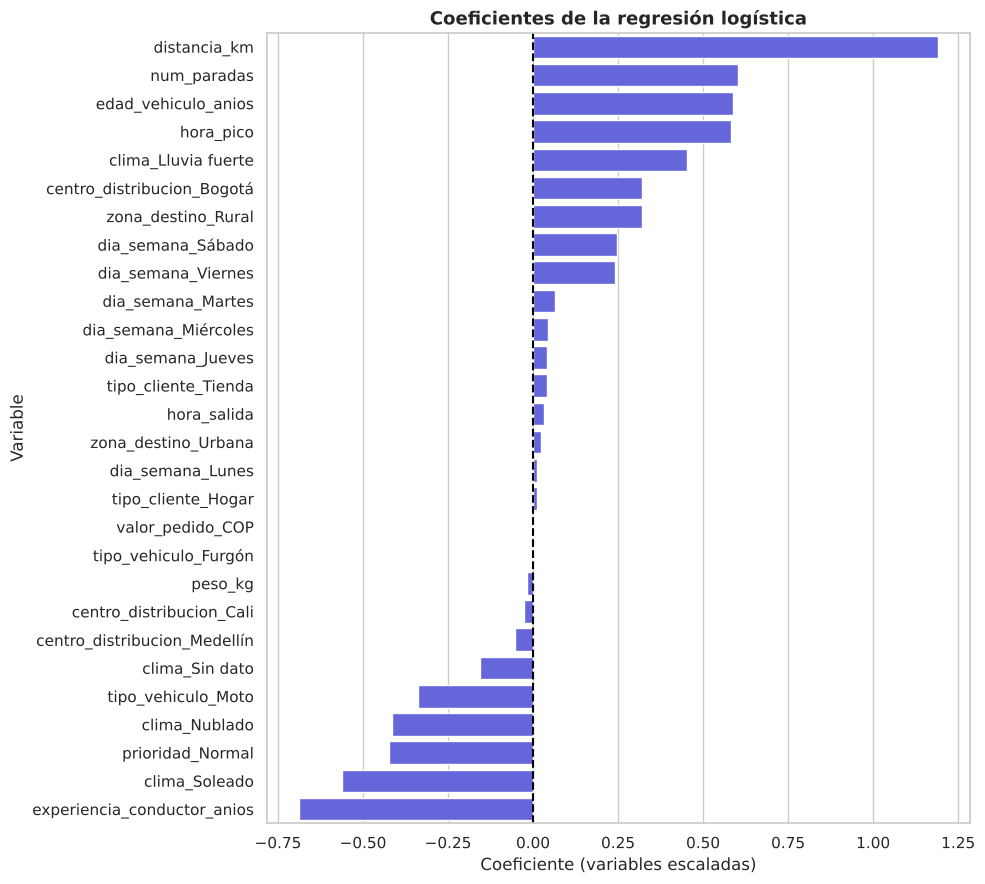

In [38]:

modelo_log = LogisticRegression(C=1, max_iter=1000)
modelo_log.fit(X_train_esc, y_train)

coeficientes = pd.DataFrame({
    "Variable": X_train_esc.columns,
    "Coeficiente": modelo_log.coef_[0].round(3)
})

coeficientes = coeficientes.sort_values("Coeficiente", ascending=False)

display(coeficientes)

plt.figure(figsize=(10, 9))

sns.barplot(
    data=coeficientes,
    x="Coeficiente",
    y="Variable",
    color="#5353EE"
)

plt.title("Coeficientes de la regresión logística")
plt.xlabel("Coeficiente (variables escaladas)")
plt.ylabel("Variable")
plt.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()


Interpretación del punto 2

Como las variables están escaladas, podemos comparar el tamaño de los coeficientes entre sí. Un coeficiente positivo significa que la variable aumenta el riesgo de que el pedido llegue tarde, y uno negativo que lo reduce. En las variables categóricas la comparación es contra la categoría de referencia que quedó por fuera con drop_first.

1. **Variables que aumentan el riesgo:** La distancia es la que más influye (1,190). Le siguen el número de paradas (0,603), la edad del vehículo (0,588) y la hora pico (0,582). También aumentan el riesgo la lluvia fuerte (0,453 frente a lluvia), el centro de Bogotá (0,319 frente a Barranquilla), la zona rural (0,319 frente a periurbana) y los despachos del sábado y el viernes (0,247 y 0,240 frente al domingo).

2. **Variables que reducen el riesgo:** La experiencia del conductor tiene el coeficiente negativo más grande (-0,688). Los climas soleado (-0,562) y nublado (-0,414) tienen menos riesgo que la lluvia. La prioridad normal (-0,423) tiene menos riesgo que la Express, y la moto (-0,337) menos que el camión.

3. **Variables que casi no influyen:** El peso, el valor del pedido y el tipo de cliente tienen coeficientes muy cercanos a 0, lo que coincide con lo que vimos en el EDA.

También hay dos resultados que vale la pena resaltar. La hora de salida como número tiene un coeficiente de solo 0,031, mientras que hora_pico tiene 0,582, lo que confirma que el efecto de la hora no es lineal. Además, la zona urbana casi no se diferencia de la periurbana (0,022), posiblemente porque la diferencia entre esas zonas ya la explica la distancia.

17. Punto 3 (Árbol de decisión: prueba de configuraciones)

In [39]:

from sklearn.tree import DecisionTreeClassifier

profundidades = [3, 5, 7, 10, None]

resultados_arbol = []

for prof in profundidades:

    modelo = DecisionTreeClassifier(max_depth=prof, random_state=42)
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    resultados_arbol.append({
        "max_depth": "Sin límite" if prof is None else prof,
        "Profundidad real": modelo.get_depth(),
        "Accuracy entrenamiento": round(accuracy_score(y_train, pred_train), 3),
        "Accuracy prueba": round(accuracy_score(y_test, pred_test), 3),
        "Recall prueba": round(recall_score(y_test, pred_test), 3),
        "F1 prueba": round(f1_score(y_test, pred_test), 3)
    })

resultados_arbol = pd.DataFrame(resultados_arbol)

display(resultados_arbol)


,max_depth,Profundidad real,Accuracy entrenamiento,Accuracy prueba,Recall prueba,F1 prueba
0,3,3,0.779,0.756,0.475,0.550
1,5,5,0.797,0.765,0.441,0.540
2,7,7,0.828,0.775,0.566,0.612
3,10,10,0.897,0.765,0.545,0.593
4,Sin límite,19,1.000,0.734,0.596,0.584


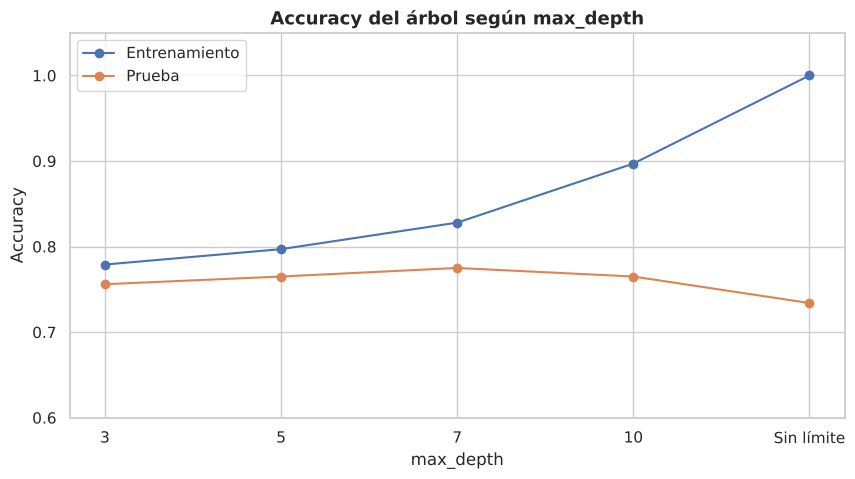

In [40]:

plt.figure(figsize=(10, 5))

plt.plot(
    resultados_arbol["max_depth"].astype(str),
    resultados_arbol["Accuracy entrenamiento"],
    marker="o",
    label="Entrenamiento"
)

plt.plot(
    resultados_arbol["max_depth"].astype(str),
    resultados_arbol["Accuracy prueba"],
    marker="o",
    label="Prueba"
)

plt.title("Accuracy del árbol según max_depth")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.ylim(0.6, 1.05)
plt.legend()
plt.show()


Interpretación del punto 3

En el árbol de decisión probamos cinco valores de max_depth, que es la cantidad máxima de niveles que puede tener el árbol.

Sin límite de profundidad el árbol creció hasta 19 niveles y obtuvo un accuracy de 1,000 en entrenamiento, pero solo 0,734 en prueba. Esto es un sobreajuste claro: el árbol se aprendió de memoria los datos de entrenamiento y no funciona igual de bien con datos nuevos. Con max_depth = 10 pasa algo parecido, aunque en menor medida (0,897 frente a 0,765).

En el otro extremo, con max_depth = 3 y 5 el árbol es demasiado simple y el recall es bajo (0,475 y 0,441), así que no detecta la mayoría de los retrasos.

Elegimos **max_depth = 7**, porque tiene el mejor accuracy en prueba (0,775), el mejor F1 (0,612) y un buen recall (0,566). Además, la diferencia entre entrenamiento y prueba es pequeña (0,828 frente a 0,775), por lo que no hay un sobreajuste fuerte. En la gráfica se ve que a partir de este punto la línea de entrenamiento sigue subiendo, mientras que la de prueba empieza a bajar.

18. Punto 4 (Árbol de decisión: modelo elegido y primeras divisiones)

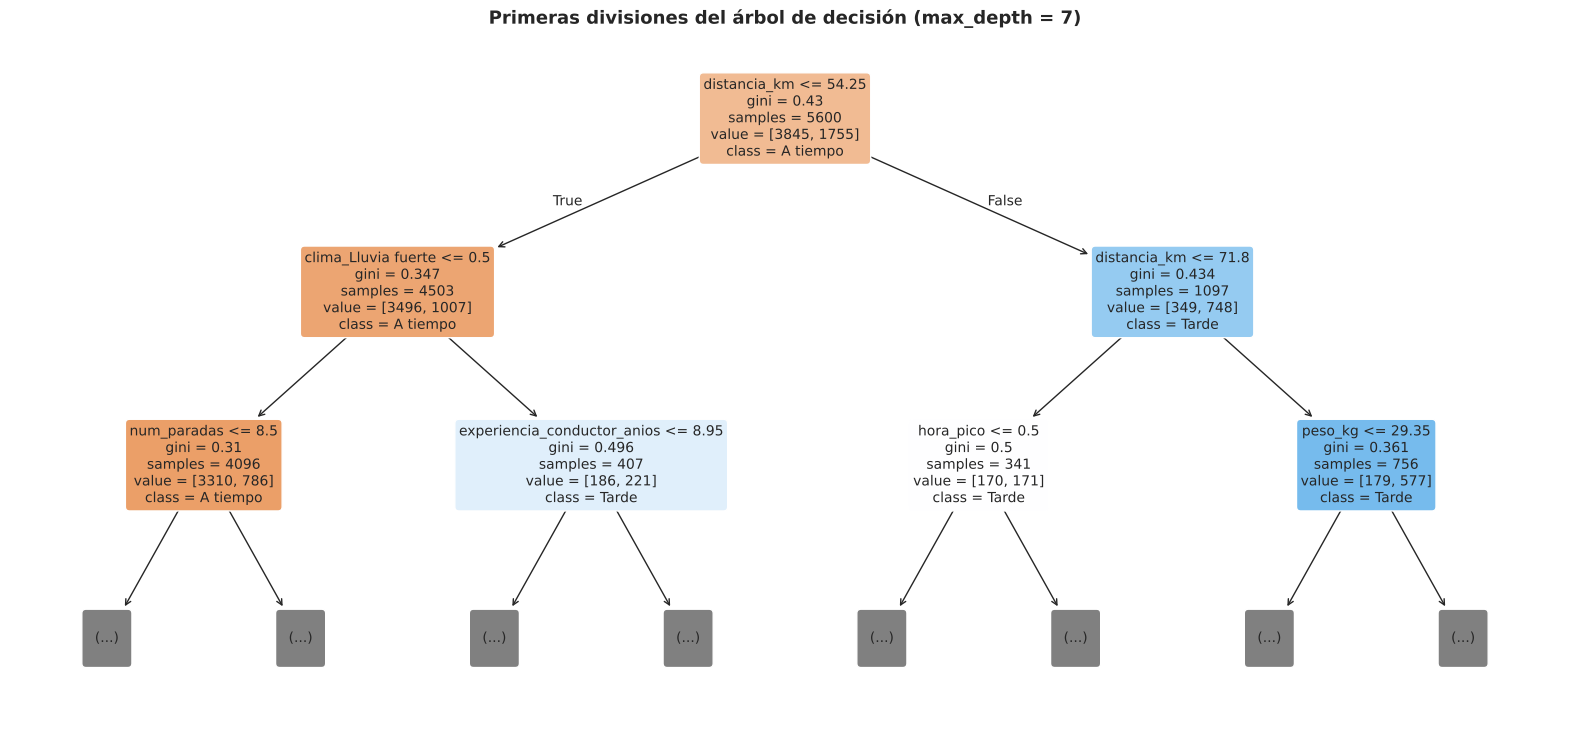

In [41]:

from sklearn.tree import plot_tree

modelo_arbol = DecisionTreeClassifier(max_depth=7, random_state=42)
modelo_arbol.fit(X_train, y_train)

plt.figure(figsize=(20, 9))

plot_tree(
    modelo_arbol,
    max_depth=2,
    feature_names=X_train.columns,
    class_names=["A tiempo", "Tarde"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Primeras divisiones del árbol de decisión (max_depth = 7)")
plt.show()


,Variable,Importancia
0,distancia_km,0.455
21,clima_Lluvia fuerte,0.104
4,experiencia_conductor_anios,0.099
2,num_paradas,0.077
7,hora_pico,0.061
5,edad_vehiculo_anios,0.057
1,peso_kg,0.051
27,prioridad_Normal,0.032
6,valor_pedido_COP,0.025
14,centro_distribucion_Bogotá,0.008


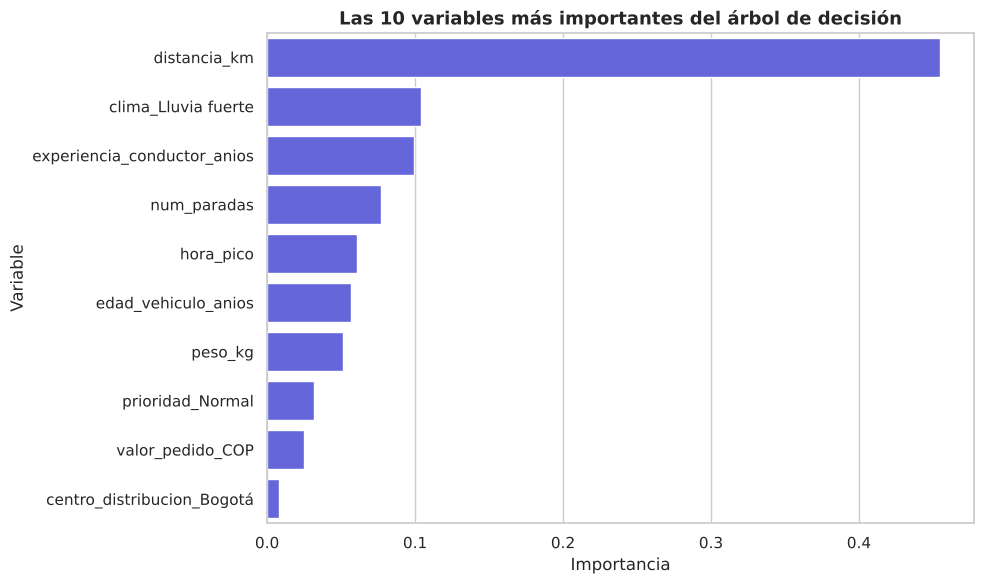

In [42]:

importancia = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": modelo_arbol.feature_importances_.round(3)
})

importancia = importancia.sort_values("Importancia", ascending=False).head(10)

display(importancia)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancia,
    x="Importancia",
    y="Variable",
    color="#5353EE"
)

plt.title("Las 10 variables más importantes del árbol de decisión")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


Interpretación del punto 4

**Primeras divisiones del árbol:**

1. La primera división es por distancia, en 54,25 km. Esto confirma que la distancia es la variable más importante para separar los pedidos tardíos de los puntuales.

2. En las rutas de 54,25 km o menos, la siguiente división es si hay lluvia fuerte. Sin lluvia fuerte el árbol separa por número de paradas (8,5). Con lluvia fuerte, el 54 % de los pedidos llega tarde (221 de 407), y el árbol separa por la experiencia del conductor (8,95 años).

3. En las rutas de más de 54,25 km, el 68 % de los pedidos llega tarde (748 de 1.097). El árbol vuelve a dividir por distancia (71,8 km). Entre 54 y 72 km la siguiente división es la hora pico, y en las rutas de más de 72 km es el peso, con un 76 % de pedidos tardíos (577 de 756).

**Importancia de las variables:** La distancia es por mucho la variable más importante (0,455), seguida de la lluvia fuerte (0,104), la experiencia del conductor (0,099), el número de paradas (0,077) y la hora pico (0,061).

Estos resultados coinciden con la regresión logística y con el EDA. Los dos modelos identifican la distancia, el clima, la experiencia del conductor, las paradas y la hora pico como las variables más relacionadas con los retrasos.

Conclusiones Fase 4

Entrenamos los dos modelos y probamos varias configuraciones de hiperparámetros en cada uno. En la regresión logística elegimos C = 1 porque tuvo el mejor recall y F1 sin sobreajuste. En el árbol de decisión elegimos max_depth = 7 porque logra el mejor desempeño en prueba sin que la diferencia con entrenamiento sea grande, mientras que el árbol sin límite mostró un sobreajuste claro.

Los dos modelos coinciden en que la distancia es la variable más importante para predecir los retrasos, seguida de factores como el clima, la experiencia del conductor, el número de paradas y la hora pico. En la fase 5 vamos a evaluar estos dos modelos con todas las métricas y a elegir el mejor para TransAndes.

Fase 5 (Evaluación)

19. Punto 1 (Regresión logística: matriz de confusión y métricas)

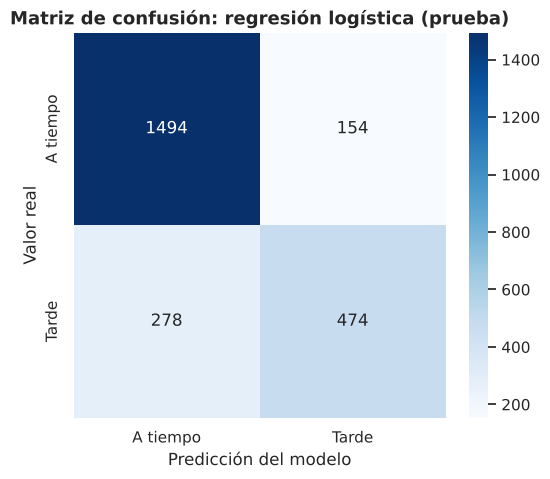

,Conjunto,Accuracy,Precision,Recall,F1
0,Entrenamiento,0.829,0.777,0.639,0.701
1,Prueba,0.820,0.755,0.630,0.687


In [43]:

from sklearn.metrics import confusion_matrix

pred_train_log = modelo_log.predict(X_train_esc)
pred_test_log = modelo_log.predict(X_test_esc)

matriz_log = confusion_matrix(y_test, pred_test_log)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["A tiempo", "Tarde"],
    yticklabels=["A tiempo", "Tarde"]
)

plt.title("Matriz de confusión: regresión logística (prueba)")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.show()

metricas_log = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Accuracy": [accuracy_score(y_train, pred_train_log), accuracy_score(y_test, pred_test_log)],
    "Precision": [precision_score(y_train, pred_train_log), precision_score(y_test, pred_test_log)],
    "Recall": [recall_score(y_train, pred_train_log), recall_score(y_test, pred_test_log)],
    "F1": [f1_score(y_train, pred_train_log), f1_score(y_test, pred_test_log)]
}).round(3)

display(metricas_log)


Interpretación del punto 1

En el conjunto de prueba hay 752 pedidos que llegaron tarde y 1.648 que llegaron a tiempo. La matriz de confusión de la regresión logística muestra lo siguiente:

1. **Verdaderos positivos (474):** Pedidos que el modelo predijo como tardíos y que sí llegaron tarde. Son los retrasos que la empresa podría prevenir.

2. **Falsos negativos (278):** Pedidos que el modelo dijo que llegarían a tiempo pero llegaron tarde. Como explicamos en la fase 1, este es el error más costoso, porque la empresa no tomaría medidas.

3. **Falsos positivos (154):** Pedidos que el modelo marcó como tardíos pero llegaron a tiempo. Generan gastos extra, pero son menos graves.

4. **Verdaderos negativos (1.494):** Pedidos puntuales que el modelo clasificó bien.

En prueba, el modelo tiene un accuracy de 0,820, es decir, acierta en el 82 % de los pedidos. La precision es de 0,755, lo que significa que cuando el modelo dice que un pedido llegará tarde, acierta el 75,5 % de las veces. El recall es de 0,630, o sea que detecta el 63 % de los pedidos que realmente llegan tarde, y el F1 es de 0,687. Las métricas en entrenamiento son muy parecidas (por ejemplo, un recall de 0,639).

20. Punto 2 (Árbol de decisión: matriz de confusión y métricas)

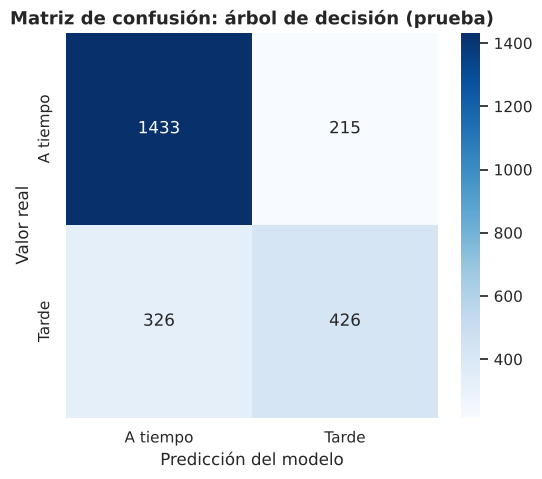

,Conjunto,Accuracy,Precision,Recall,F1
0,Entrenamiento,0.828,0.776,0.632,0.697
1,Prueba,0.775,0.665,0.566,0.612


In [44]:

pred_train_arbol = modelo_arbol.predict(X_train)
pred_test_arbol = modelo_arbol.predict(X_test)

matriz_arbol = confusion_matrix(y_test, pred_test_arbol)

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_arbol,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["A tiempo", "Tarde"],
    yticklabels=["A tiempo", "Tarde"]
)

plt.title("Matriz de confusión: árbol de decisión (prueba)")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.show()

metricas_arbol = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Accuracy": [accuracy_score(y_train, pred_train_arbol), accuracy_score(y_test, pred_test_arbol)],
    "Precision": [precision_score(y_train, pred_train_arbol), precision_score(y_test, pred_test_arbol)],
    "Recall": [recall_score(y_train, pred_train_arbol), recall_score(y_test, pred_test_arbol)],
    "F1": [f1_score(y_train, pred_train_arbol), f1_score(y_test, pred_test_arbol)]
}).round(3)

display(metricas_arbol)


Interpretación del punto 2

La matriz de confusión del árbol de decisión en el conjunto de prueba muestra lo siguiente:

1. **Verdaderos positivos (426):** Pedidos tardíos que el modelo detectó correctamente.

2. **Falsos negativos (326):** Pedidos que llegaron tarde y que el modelo no detectó.

3. **Falsos positivos (215):** Pedidos puntuales que el modelo marcó como tardíos.

4. **Verdaderos negativos (1.433):** Pedidos puntuales clasificados correctamente.

En prueba, el árbol tiene un accuracy de 0,775, una precision de 0,665, un recall de 0,566 y un F1 de 0,612. Esto quiere decir que detecta el 56,6 % de los retrasos, y que cuando predice que un pedido llegará tarde acierta el 66,5 % de las veces. En entrenamiento sus métricas son más altas (accuracy de 0,828 y F1 de 0,697), lo que analizamos en el siguiente punto.

21. Punto 3 (Entrenamiento vs prueba: análisis de sobreajuste)

,Modelo,Conjunto,Accuracy,Precision,Recall,F1
0,Regresión logística,Entrenamiento,0.829,0.777,0.639,0.701
1,Regresión logística,Prueba,0.820,0.755,0.630,0.687
2,Árbol de decisión,Entrenamiento,0.828,0.776,0.632,0.697
3,Árbol de decisión,Prueba,0.775,0.665,0.566,0.612


,Modelo,Diferencia accuracy (entrenamiento - prueba),Diferencia F1 (entrenamiento - prueba)
0,Regresión logística,0.009,0.014
1,Árbol de decisión,0.053,0.085


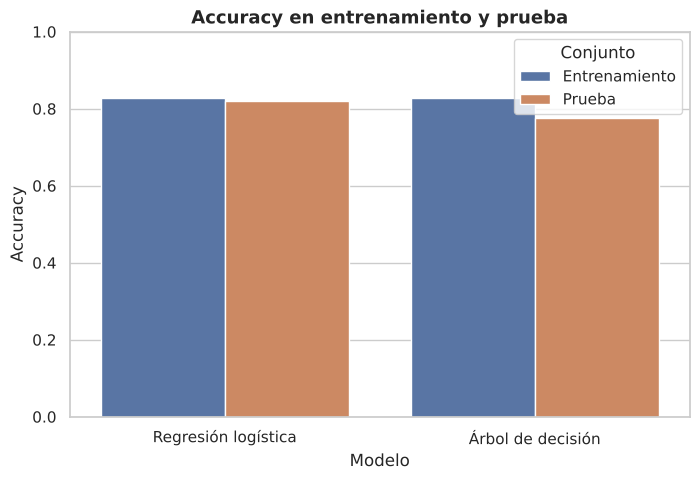

In [45]:

tabla_sobreajuste = pd.concat([
    metricas_log.assign(Modelo="Regresión logística"),
    metricas_arbol.assign(Modelo="Árbol de decisión")
])

tabla_sobreajuste = tabla_sobreajuste[["Modelo", "Conjunto", "Accuracy", "Precision", "Recall", "F1"]]

display(tabla_sobreajuste.reset_index(drop=True))

diferencias = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "Diferencia accuracy (entrenamiento - prueba)": [
        metricas_log["Accuracy"][0] - metricas_log["Accuracy"][1],
        metricas_arbol["Accuracy"][0] - metricas_arbol["Accuracy"][1]
    ],
    "Diferencia F1 (entrenamiento - prueba)": [
        metricas_log["F1"][0] - metricas_log["F1"][1],
        metricas_arbol["F1"][0] - metricas_arbol["F1"][1]
    ]
}).round(3)

display(diferencias)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=tabla_sobreajuste,
    x="Modelo",
    y="Accuracy",
    hue="Conjunto"
)

plt.title("Accuracy en entrenamiento y prueba")
plt.xlabel("Modelo")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend(title="Conjunto")
plt.show()


Interpretación del punto 3

1. **Regresión logística:** La diferencia entre entrenamiento y prueba es muy pequeña, de 0,009 en accuracy y 0,014 en F1. Esto indica que el modelo no está sobreajustado y que funciona casi igual con pedidos que no había visto.

2. **Árbol de decisión:** La diferencia es más grande, de 0,053 en accuracy y 0,085 en F1. Esto muestra un sobreajuste leve: el árbol se ajusta mejor a los datos de entrenamiento que a los datos nuevos. Aun así, es mucho menor que el del árbol sin límite de profundidad que probamos en la fase 4, que tenía una diferencia de 0,266 en accuracy (1,000 frente a 0,734). Esto confirma que limitar max_depth a 7 sí ayudó a controlar el sobreajuste.

22. Punto 4 (Tabla comparativa de los modelos)

,Modelo,Accuracy,Precision,Recall,F1
0,Regresión logística (C = 1),0.820,0.755,0.630,0.687
1,Árbol de decisión (max_depth = 7),0.775,0.665,0.566,0.612
2,Referencia: siempre a tiempo,0.687,0.000,0.000,0.000


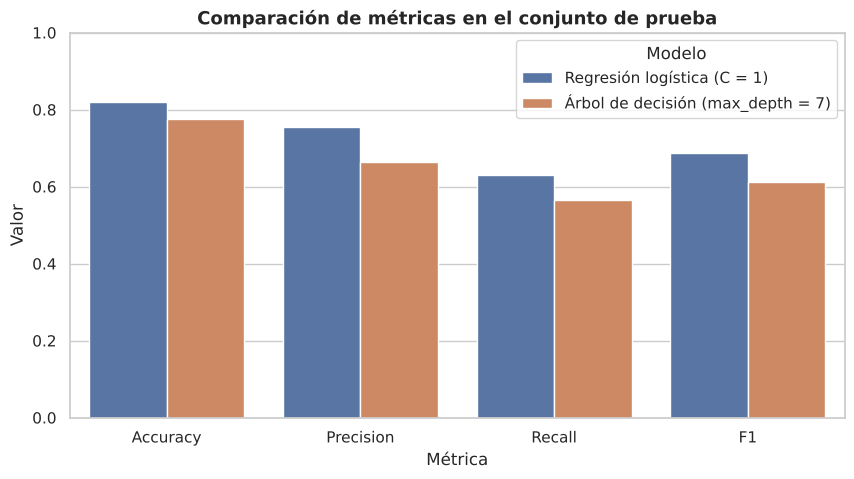

In [46]:

pred_siempre_a_tiempo = np.zeros(len(y_test), dtype=int)

tabla_comparativa = pd.DataFrame({
    "Modelo": [
        "Regresión logística (C = 1)",
        "Árbol de decisión (max_depth = 7)",
        "Referencia: siempre a tiempo"
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_test_log),
        accuracy_score(y_test, pred_test_arbol),
        accuracy_score(y_test, pred_siempre_a_tiempo)
    ],
    "Precision": [
        precision_score(y_test, pred_test_log),
        precision_score(y_test, pred_test_arbol),
        precision_score(y_test, pred_siempre_a_tiempo, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_test_log),
        recall_score(y_test, pred_test_arbol),
        recall_score(y_test, pred_siempre_a_tiempo)
    ],
    "F1": [
        f1_score(y_test, pred_test_log),
        f1_score(y_test, pred_test_arbol),
        f1_score(y_test, pred_siempre_a_tiempo)
    ]
}).round(3)

display(tabla_comparativa)

tabla_grafica = tabla_comparativa.iloc[:2].melt(
    id_vars="Modelo",
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_grafica,
    x="Métrica",
    y="Valor",
    hue="Modelo"
)

plt.title("Comparación de métricas en el conjunto de prueba")
plt.xlabel("Métrica")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.legend(title="Modelo")
plt.show()


Interpretación del punto 4

En el conjunto de prueba, la regresión logística es mejor que el árbol de decisión en las cuatro métricas: accuracy (0,820 frente a 0,775), precision (0,755 frente a 0,665), recall (0,630 frente a 0,566) y F1 (0,687 frente a 0,612).

En la tabla también incluimos como referencia un modelo que siempre dice que el pedido llegará a tiempo. Este modelo tendría un accuracy de 0,687 sin detectar ni un solo retraso (recall de 0). Esto muestra que, como solo el 31 % de los pedidos llega tarde, el accuracy por sí solo puede engañar, y por eso es necesario mirar el recall y el F1 para saber si un modelo realmente sirve para detectar los retrasos.

23. Punto 5 (Elección del mejor modelo para TransAndes)

In [47]:

tabla_errores = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "Retrasos detectados (VP)": [matriz_log[1, 1], matriz_arbol[1, 1]],
    "Retrasos no detectados (FN)": [matriz_log[1, 0], matriz_arbol[1, 0]],
    "Falsas alarmas (FP)": [matriz_log[0, 1], matriz_arbol[0, 1]],
    "Puntuales bien clasificados (VN)": [matriz_log[0, 0], matriz_arbol[0, 0]]
})

tabla_errores["% de retrasos detectados"] = (
    tabla_errores["Retrasos detectados (VP)"] / y_test.sum() * 100
).round(2)

print("Total de pedidos tardíos en prueba:", y_test.sum())

display(tabla_errores)


Total de pedidos tardíos en prueba: 752


,Modelo,Retrasos detectados (VP),Retrasos no detectados (FN),Falsas alarmas (FP),Puntuales bien clasificados (VN),% de retrasos detectados
0,Regresión logística,474,278,154,1494,63.03
1,Árbol de decisión,426,326,215,1433,56.65


Interpretación del punto 5

Elegimos la **regresión logística** como el mejor modelo para TransAndes por las siguientes razones:

1. **Tiene el mejor recall:** En la fase 1 definimos que el error más costoso para la empresa es el falso negativo, es decir, decir que un pedido llegará a tiempo y que llegue tarde. Por eso priorizamos el recall de la clase Sí. La regresión logística detecta el 63,03 % de los retrasos, frente a 56,65 % del árbol.

2. **Comete menos falsos negativos:** Deja pasar 278 retrasos, mientras que el árbol deja pasar 326. Son 48 pedidos tardíos más que la empresa podría prevenir.

3. **También tiene menos falsos positivos:** Genera 154 falsas alarmas frente a 215 del árbol, así que no tuvimos que sacrificar un error por el otro.

4. **No está sobreajustada:** Su desempeño en entrenamiento y en prueba es casi igual, por lo que esperamos que funcione de forma parecida con pedidos nuevos.

5. **Es fácil de explicar:** Con el signo de sus coeficientes la gerencia puede entender qué condiciones aumentan o reducen el riesgo de retraso.

Sin embargo, el modelo todavía no detecta 278 de los 752 retrasos (cerca del 37 %), así que no reemplaza el criterio del equipo de operaciones. Debe usarse como una herramienta de apoyo para priorizar los pedidos con más riesgo.

Conclusiones Fase 5

Evaluamos los dos modelos con la matriz de confusión y las métricas de accuracy, precision, recall y F1, tanto en entrenamiento como en prueba. La regresión logística fue mejor en todas las métricas del conjunto de prueba y no mostró sobreajuste, mientras que el árbol de decisión tuvo un sobreajuste leve.

Elegimos la regresión logística porque detecta más retrasos y comete menos falsos negativos, que es el error más costoso para TransAndes según la fase 1. También vimos que el accuracy por sí solo puede engañar, porque un modelo que siempre dice "a tiempo" tendría 68,7 % de accuracy sin detectar ningún retraso.

Fase 6 (Recomendaciones)

24. Punto 1 (Variables más relacionadas con los retrasos)

In [48]:

importancia_total = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia árbol": modelo_arbol.feature_importances_.round(3)
})

tabla_variables = coeficientes.merge(importancia_total, on="Variable")

tabla_variables = tabla_variables.rename(columns={"Coeficiente": "Coeficiente logística"})

tabla_variables = tabla_variables.sort_values("Importancia árbol", ascending=False).head(10)

display(tabla_variables.reset_index(drop=True))


,Variable,Coeficiente logística,Importancia árbol
0,distancia_km,1.190,0.455
1,clima_Lluvia fuerte,0.453,0.104
2,experiencia_conductor_anios,-0.688,0.099
3,num_paradas,0.603,0.077
4,hora_pico,0.582,0.061
5,edad_vehiculo_anios,0.588,0.057
6,peso_kg,-0.018,0.051
7,prioridad_Normal,-0.423,0.032
8,valor_pedido_COP,0.001,0.025
9,centro_distribucion_Bogotá,0.319,0.008


Interpretación del punto 1

En la tabla juntamos los resultados de los dos modelos. Si además los comparamos con lo que encontramos en el EDA, las variables que más se relacionan con los retrasos son las siguientes:

1. **Distancia:** Es la variable más importante en todo el análisis. En el EDA tuvo la correlación más alta con las entregas tardías (0,41) y la mediana de los pedidos tardíos fue de 41,6 km frente a 15,9 km de los puntuales. En la regresión logística tiene el coeficiente más grande (1,190) y en el árbol explica casi la mitad de la importancia total (0,455). Además, es la primera división del árbol: en las rutas de más de 54 km llega tarde el 68 % de los pedidos. Esto también explica por qué la zona rural tiene tantos retrasos (69 %), ya que son las rutas más largas.

2. **Clima con lluvia fuerte:** En el EDA el 60 % de los pedidos con lluvia fuerte llegó tarde, frente a 23 % con sol. En los dos modelos aparece entre las variables más importantes.

3. **Experiencia del conductor:** Es la variable que más reduce el riesgo. Tiene el coeficiente negativo más grande en la logística (-0,688) y en el árbol aparece justo después de la lluvia fuerte, lo que sugiere que un conductor con experiencia maneja mejor las condiciones difíciles.

4. **Número de paradas:** Cada parada suma tiempo a la ruta. En el EDA los pedidos tardíos tenían más paradas y en los dos modelos aparece con un peso importante.

5. **Hora pico:** Los pedidos que salen entre las 7 y las 9 o entre las 17 y las 19 llegan tarde el 41,5 % de las veces, frente a 25,85 % en el resto del día. En la logística tiene un coeficiente de 0,582.

6. **Edad del vehículo y prioridad Express:** Los vehículos más viejos y los pedidos Express, que tienen una ventana de entrega más corta, también aumentan el riesgo de retraso.

Por otro lado, el tipo de cliente y el valor del pedido casi no tienen relación con los retrasos. El peso aparece en el árbol solo dentro de las rutas largas, pero en el EDA y en la logística no mostró una relación clara. El centro de Bogotá tuvo más retrasos que los demás en el EDA (38 %) y la logística lo confirma (0,319), aunque en el árbol tiene poca importancia.

En resumen, los retrasos dependen más de cómo se planea el despacho (la ruta, la hora, el conductor y el vehículo) que del tipo de cliente o del pedido.

25. Punto 2 (Recomendaciones para la gerencia de operaciones)

Recomendaciones

Con base en los resultados, le proponemos a la gerencia de operaciones de TransAndes las siguientes acciones:

1. **Usar el modelo como una alerta de riesgo al momento del despacho.** Antes de que salga cada vehículo, la regresión logística puede marcar los pedidos con riesgo de llegar tarde. En nuestras pruebas detectó el 63 % de los retrasos, y cuando marcó un pedido como tardío acertó en el 75,5 % de los casos. Con esa alerta el equipo puede actuar antes, por ejemplo cambiando el conductor o el vehículo, o avisándole al cliente con tiempo.

2. **Planear de forma diferente las rutas largas y rurales.** Como en las rutas de más de 54 km llega tarde el 68 % de los pedidos, recomendamos que salgan más temprano o que la ventana de entrega que se le promete al cliente sea más amplia. Así la promesa de entrega queda más cerca de lo que la operación realmente puede cumplir.

3. **Evitar despachar en horas pico cuando sea posible.** Los pedidos que salen fuera de las horas pico llegan tarde con mucha menos frecuencia (25,85 % frente a 41,5 %), por eso recomendamos mover a otras horas los despachos que no sean urgentes. Si no se puede cambiar la hora, al menos esos pedidos deberían ir con los conductores con más experiencia.

4. **Asignar a los conductores con más experiencia a los pedidos más difíciles.** La experiencia es lo que más reduce el riesgo, sobre todo cuando hay lluvia fuerte. Por eso recomendamos darles las rutas rurales, los pedidos Express y los días de mal clima. A los conductores nuevos se les puede acompañar o capacitar en estas rutas.

5. **Revisar el pronóstico del clima antes de despachar.** Con lluvia fuerte el 60 % de los pedidos llega tarde. En esos días se puede salir antes, reducir el número de paradas por ruta o avisarle al cliente sobre un posible retraso.

6. **Revisar la operación del centro de Bogotá.** Es el centro con más retrasos (38 %) y la regresión logística confirma que sigue teniendo más riesgo aun teniendo en cuenta las demás variables. Esto indica que hay algo propio de ese centro, como el tráfico o la forma en que se organizan los despachos, que vale la pena investigar.

26. Punto 3 (Limitaciones del análisis)

Limitaciones

Aunque los resultados son útiles, nuestro análisis tiene algunas limitaciones que hay que tener en cuenta:

1. **El modelo no detecta todos los retrasos.** La regresión logística deja pasar 278 de los 752 pedidos tardíos del conjunto de prueba, cerca del 37 %. Por eso debe usarse como apoyo y no como la única herramienta para tomar decisiones.

2. **La forma en que imputamos los nulos.** Calculamos las medianas con toda la base antes de dividir en entrenamiento y prueba. Lo más correcto sería calcularlas solo con los datos de entrenamiento, para que el conjunto de prueba no aporte información al modelo. Además, el 45 % de las filas tenía al menos un dato imputado, lo que puede ocultar parte de la variación real de los datos.

3. **Elegimos los hiperparámetros con el conjunto de prueba.** Comparamos las configuraciones con los mismos datos con los que después evaluamos los modelos, por lo que los resultados podrían ser un poco optimistas. Lo ideal sería usar un conjunto de validación aparte.

4. **Faltan variables importantes.** La base no incluye información como el tráfico real, el estado de las vías, el tiempo que se demora cada parada o la causa del retraso. Esto podría explicar, por ejemplo, por qué Bogotá tiene más retrasos.

5. **Los datos son de un solo año.** Solo tenemos información de 2025, así que no sabemos si los patrones se mantienen en otras épocas o si cambian con nuevas rutas o temporadas.

6. **Relación no significa causa.** Los modelos muestran qué variables están asociadas con los retrasos, pero no prueban que una variable los cause. Por ejemplo, la experiencia del conductor podría estar relacionada con el tipo de rutas que se le asignan a cada uno.

Conclusión general del proyecto

Al inicio del proyecto TransAndes se preguntaba si con la información disponible al momento del despacho era posible predecir qué pedidos llegarían tarde, y qué condiciones aumentan ese riesgo.

Con base en nuestro análisis, la respuesta a la primera pregunta es sí, aunque con límites. La regresión logística detecta el 63 % de los pedidos que llegan tarde y acierta en el 75,5 % de las alertas que genera, lo que es mucho mejor que no tener ningún modelo. No es perfecta, pero le permite a la empresa anticiparse en una buena parte de los casos.

Sobre la segunda pregunta, encontramos que el riesgo de retraso aumenta principalmente con la distancia, la lluvia fuerte, el número de paradas, la salida en horas pico, la edad del vehículo y la prioridad Express, mientras que la experiencia del conductor lo reduce. Varias de estas condiciones dependen de la forma en que la empresa planea sus despachos, por eso creemos que con las recomendaciones propuestas TransAndes puede reducir sus retrasos y cumplir mejor con lo que les promete a sus clientes.